In [1]:
# -*- coding: utf-8 -*-


import os
import warnings
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

# =============================================================================
# 0. CONFIGURACIÓN (edita solo esta sección)
# =============================================================================
RUTA_EXCEL = "Proyecto Econometria.xlsx"
HOJA = "BASE DE DATOS COMPLETA"
COL_FECHA = "FECHA MES"
COL_Y = "INPC"
COLS_X = ["C. BASICA", "PETROLEO C.", "TIPO CAMBIO", "TIIE 28"]
ETIQUETAS = {                       # nombres bonitos para tablas y gráficas
    "INPC": "INPC",
    "C. BASICA": "Canasta básica",
    "PETROLEO C.": "Petróleo crudo",
    "TIPO CAMBIO": "Tipo de cambio",
    "TIIE 28": "TIIE 28 días",
}
ALPHA = 0.05                        # nivel de significancia (elegirlo ANTES de ver resultados)
UMBRAL_VIF = 5                      # alerta; 10 = criterio más laxo (no es regla universal)
LAGS_BG = 12                        # rezagos para Breusch-Godfrey (datos mensuales)
SUBMUESTRA_INICIO = "2000-01-01"    # para análisis de sensibilidad (excluye crisis 1995-99)
CARPETA_SALIDA = "resultados_econometria"

os.makedirs(CARPETA_SALIDA, exist_ok=True)
REPORTE = []                        # se va llenando y se guarda como .txt


def say(texto="", titulo=False):
    """Imprime y guarda en el reporte."""
    if titulo:
        texto = "\n" + "=" * 78 + f"\n{texto}\n" + "=" * 78
    print(texto)
    REPORTE.append(texto)


def etq(c):
    return ETIQUETAS.get(c, c)


# =============================================================================
# 1. CARGA Y VALIDACIÓN
# =============================================================================
def cargar_datos():
    df = pd.read_excel(RUTA_EXCEL, sheet_name=HOJA)
    df.columns = df.columns.astype(str).str.strip()      # ej.: 'PETROLEO C. ' trae un espacio al final
    faltan = [c for c in [COL_FECHA, COL_Y] + COLS_X if c not in df.columns]
    if faltan:
        raise KeyError(f"No encontré estas columnas en la hoja '{HOJA}': {faltan}. "
                       f"Columnas disponibles: {list(df.columns)}")
    df = df[[COL_FECHA, COL_Y] + COLS_X].copy()
    df[COL_FECHA] = pd.to_datetime(df[COL_FECHA])
    for c in [COL_Y] + COLS_X:
        df[c] = pd.to_numeric(df[c], errors="coerce")
    df = df.sort_values(COL_FECHA).set_index(COL_FECHA)

    faltantes = df.isna().sum()
    if faltantes.sum() > 0:
        say("AVISO: hay valores faltantes; se eliminan filas incompletas.")
        say(faltantes.to_string())
    df = df.dropna()
    if df.index.duplicated().any():
        raise ValueError("Hay fechas duplicadas en la base.")
    return df


# =============================================================================
# 2. NÚCLEO DE MCO (implementado con numpy para ver cada fórmula)
# =============================================================================
def ols(y, X, nombres, cov="nonrobust", maxlags=None):
    """
    MCO:  beta = (X'X)^-1 X'y
    X debe incluir la columna de constantes. cov: 'nonrobust' | 'HC3' | 'HAC'
    """
    y = np.asarray(y, float)
    X = np.asarray(X, float)
    n, p = X.shape                       # p = k + 1 (con constante)
    k = p - 1
    if np.linalg.matrix_rank(X) < p:
        raise np.linalg.LinAlgError("Colinealidad perfecta: X no tiene rango completo.")

    XtX_inv = np.linalg.inv(X.T @ X)
    beta = XtX_inv @ X.T @ y
    fitted = X @ beta
    resid = y - fitted
    gl = n - p
    rss = float(resid @ resid)
    tss = float(((y - y.mean()) ** 2).sum())
    ess = tss - rss
    sigma2 = rss / gl
    h = np.einsum("ij,jk,ik->i", X, XtX_inv, X)          # apalancamiento (diag de H)

    if cov == "nonrobust":
        V = sigma2 * XtX_inv
    elif cov == "HC3":
        meat = X.T @ (X * (resid / (1 - h))[:, None] ** 2)
        V = XtX_inv @ meat @ XtX_inv
    elif cov == "HAC":
        L = maxlags if maxlags is not None else int(np.floor(4 * (n / 100) ** (2 / 9)))
        Xe = X * resid[:, None]
        S = Xe.T @ Xe
        for lag in range(1, L + 1):
            w = 1 - lag / (L + 1)                         # kernel de Bartlett
            G = Xe[lag:].T @ Xe[:-lag]
            S += w * (G + G.T)
        V = XtX_inv @ S @ XtX_inv
    else:
        raise ValueError("cov desconocido")

    se = np.sqrt(np.diag(V))
    t = beta / se
    pval = 2 * stats.t.sf(np.abs(t), gl)
    tcrit = stats.t.ppf(1 - ALPHA / 2, gl)
    ic_inf, ic_sup = beta - tcrit * se, beta + tcrit * se

    r2 = ess / tss
    r2_adj = 1 - (1 - r2) * (n - 1) / gl
    F = (ess / k) / sigma2
    pF = stats.f.sf(F, k, gl)
    loglik = -n / 2 * (np.log(2 * np.pi) + np.log(rss / n) + 1)
    aic = -2 * loglik + 2 * p
    bic = -2 * loglik + np.log(n) * p

    tabla = pd.DataFrame({
        "Coef.": beta, "Error est.": se, "t": t, "Valor p": pval,
        "IC 95% inf": ic_inf, "IC 95% sup": ic_sup,
    }, index=nombres)
    tabla["Signif."] = np.where(pval < 0.01, "***", np.where(pval < 0.05, "**",
                         np.where(pval < 0.10, "*", "")))

    return dict(
        tabla=tabla, beta=beta, se=se, V=V, XtX_inv=XtX_inv, resid=resid, fitted=fitted,
        n=n, k=k, gl=gl, rss=rss, tss=tss, ess=ess, sigma=np.sqrt(sigma2), r2=r2,
        r2_adj=r2_adj, F=F, pF=pF, loglik=loglik, aic=aic, bic=bic, h=h,
        y=y, X=X, nombres=nombres, cov=cov,
    )


def wald_F(m, R, r=None):
    """Prueba F de restricciones lineales R*beta = r (bajo la matriz de covarianzas de m)."""
    R = np.atleast_2d(R).astype(float)
    r = np.zeros(R.shape[0]) if r is None else np.asarray(r, float)
    q = R.shape[0]
    d = R @ m["beta"] - r
    W = d @ np.linalg.inv(R @ m["V"] @ R.T) @ d
    F = W / q
    return F, stats.f.sf(F, q, m["gl"])


def regresion(df, y_col, x_cols, cov="nonrobust"):
    X = np.column_stack([np.ones(len(df)), df[x_cols].values])
    nombres = ["Constante"] + [etq(c) for c in x_cols]
    return ols(df[y_col].values, X, nombres, cov=cov)


# =============================================================================
# 3. DIAGNÓSTICO DE SUPUESTOS
# =============================================================================
def aux_r2(y, X):
    """R2 de una regresión auxiliar (X con constante)."""
    b = np.linalg.lstsq(X, y, rcond=None)[0]
    e = y - X @ b
    tss = ((y - y.mean()) ** 2).sum()
    return 1 - (e @ e) / tss if tss > 0 else 0.0


def breusch_pagan(m):
    e2 = m["resid"] ** 2
    r2 = aux_r2(e2 / e2.mean(), m["X"])
    lm = m["n"] * r2
    return lm, stats.chi2.sf(lm, m["k"])


def white_test(m):
    X = m["X"][:, 1:]
    cols = [np.ones(m["n"])] + [X[:, j] for j in range(X.shape[1])]
    for i in range(X.shape[1]):
        for j in range(i, X.shape[1]):
            cols.append(X[:, i] * X[:, j])
    Z = np.column_stack(cols)
    # eliminar columnas redundantes
    q, rr = np.linalg.qr(Z)
    keep = np.abs(np.diag(rr)) > 1e-10
    Z = Z[:, keep]
    r2 = aux_r2(m["resid"] ** 2, Z)
    lm = m["n"] * r2
    gl = Z.shape[1] - 1
    return lm, stats.chi2.sf(lm, gl), gl


def durbin_watson(e):
    return float(np.sum(np.diff(e) ** 2) / np.sum(e ** 2))


def breusch_godfrey(m, lags):
    e = m["resid"]
    L = np.column_stack([np.concatenate([np.zeros(l), e[:-l]]) for l in range(1, lags + 1)])
    Z = np.column_stack([m["X"], L])
    r2 = aux_r2(e, Z)
    lm = m["n"] * r2
    return lm, stats.chi2.sf(lm, lags)


def reset_ramsey(m, potencias=(2, 3)):
    extra = np.column_stack([m["fitted"] ** p for p in potencias])
    Xa = np.column_stack([m["X"], extra])
    nombres = m["nombres"] + [f"yhat^{p}" for p in potencias]
    ma = ols(m["y"], Xa, nombres)
    q = len(potencias)
    F = ((m["rss"] - ma["rss"]) / q) / (ma["rss"] / ma["gl"])
    return F, stats.f.sf(F, q, ma["gl"])


def pruebas_supuestos(m, lags_bg):
    filas = []
    lm, p = breusch_pagan(m)
    filas.append(("Breusch-Pagan", "Homocedasticidad", lm, p, "Rechaza H0 = hay heterocedasticidad"))
    lm, p, gl = white_test(m)
    filas.append(("White", "Homocedasticidad", lm, p, "Rechaza H0 = hay heterocedasticidad"))
    lm, p = breusch_godfrey(m, lags_bg)
    filas.append((f"Breusch-Godfrey ({lags_bg} rez.)", "No autocorrelación", lm, p,
                  "Rechaza H0 = hay autocorrelación"))
    jb = stats.jarque_bera(m["resid"])
    filas.append(("Jarque-Bera", "Normalidad de residuos", jb.statistic, jb.pvalue,
                  "Rechaza H0 = residuos no normales"))
    if m["n"] <= 5000:
        sw = stats.shapiro(m["resid"])
        filas.append(("Shapiro-Wilk", "Normalidad de residuos", sw.statistic, sw.pvalue,
                      "Rechaza H0 = residuos no normales"))
    F, p = reset_ramsey(m)
    filas.append(("RESET de Ramsey", "Forma funcional correcta", F, p,
                  "Rechaza H0 = posible mala especificación"))
    t = pd.DataFrame(filas, columns=["Prueba", "H0", "Estadístico", "Valor p", "Lectura"])
    t["¿Rechaza H0?"] = np.where(t["Valor p"] < ALPHA, "Sí", "No")
    return t


# =============================================================================
# 4. MULTICOLINEALIDAD
# =============================================================================
def tabla_vif(df, x_cols):
    X = df[x_cols].values
    filas = []
    for j, c in enumerate(x_cols):
        otros = np.delete(X, j, axis=1)
        Z = np.column_stack([np.ones(len(X)), otros])
        r2j = aux_r2(X[:, j], Z)
        vif = 1 / (1 - r2j)
        filas.append((etq(c), r2j, vif, 1 / vif))
    t = pd.DataFrame(filas, columns=["Variable", "R2 auxiliar", "VIF", "Tolerancia"]).set_index("Variable")
    t["Alerta"] = np.where(t["VIF"] >= 10, "VIF >= 10", np.where(t["VIF"] >= UMBRAL_VIF, f"VIF >= {UMBRAL_VIF}", "OK"))
    return t


def belsley(m):
    """Índices de condición y proporciones de varianza (Belsley, Kuh y Welsch)."""
    X = m["X"]
    Xs = X / np.sqrt((X ** 2).sum(axis=0))           # columnas con norma 1
    U, s, Vt = np.linalg.svd(Xs, full_matrices=False)
    V = Vt.T
    ic = s.max() / s
    phi = (V ** 2) / (s ** 2)
    prop = phi / phi.sum(axis=1, keepdims=True)       # filas = variables
    out = pd.DataFrame(prop.T, columns=m["nombres"])
    out.insert(0, "Índice de condición", ic)
    out.index = [f"dim {i+1}" for i in range(len(ic))]
    return out


# =============================================================================
# 5. OBSERVACIONES INFLUYENTES
# =============================================================================
def influencia(m, fechas):
    e, h, n, p, s2 = m["resid"], m["h"], m["n"], m["k"] + 1, m["rss"] / m["gl"]
    r_int = e / np.sqrt(s2 * (1 - h))                                   # estandarizado
    s2_i = (m["rss"] - e ** 2 / (1 - h)) / (m["gl"] - 1)                # sigma^2 sin la obs. i
    r_ext = e / np.sqrt(s2_i * (1 - h))                                 # estudentizado externo
    cook = (r_int ** 2 / p) * (h / (1 - h))
    dff = r_ext * np.sqrt(h / (1 - h))
    return pd.DataFrame({
        "Residuo": e, "Apalanc. h": h, "Res. estudentizado": r_ext,
        "Cook D": cook, "DFFITS": dff,
    }, index=fechas)


# =============================================================================
# 6. GRÁFICAS
# =============================================================================
def guardar(fig, nombre):
    ruta = os.path.join(CARPETA_SALIDA, nombre)
    fig.tight_layout()
    fig.savefig(ruta, dpi=150)
    plt.close(fig)
    return ruta


def grafica_series(df):
    cols = [COL_Y] + COLS_X
    fig, axes = plt.subplots(len(cols), 1, figsize=(10, 2.2 * len(cols)), sharex=True)
    for ax, c in zip(axes, cols):
        ax.plot(df.index, df[c], lw=1)
        ax.set_ylabel(etq(c), fontsize=8)
        ax.grid(alpha=.3)
    axes[0].set_title("Series de tiempo de las variables")
    return guardar(fig, "01_series_tiempo.png")


def grafica_correlaciones(df):
    import seaborn as sns
    cols = [COL_Y] + COLS_X
    C = df[cols].corr()
    C.index = C.columns = [etq(c) for c in cols]
    fig, ax = plt.subplots(figsize=(6.5, 5))
    sns.heatmap(C, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax)
    ax.set_title("Matriz de correlaciones")
    return guardar(fig, "02_correlaciones.png")


def grafica_dispersion(df):
    fig, axes = plt.subplots(1, len(COLS_X), figsize=(4 * len(COLS_X), 3.5))
    for ax, c in zip(axes, COLS_X):
        ax.scatter(df[c], df[COL_Y], s=8, alpha=.6)
        b = np.polyfit(df[c], df[COL_Y], 1)
        xs = np.linspace(df[c].min(), df[c].max(), 50)
        ax.plot(xs, np.polyval(b, xs), "r", lw=1.2)
        ax.set_xlabel(etq(c)); ax.set_ylabel(etq(COL_Y)); ax.grid(alpha=.3)
    return guardar(fig, "03_dispersion_Y_vs_X.png")


def grafica_residuos(m, fechas, nombre="04_diagnostico_residuos.png"):
    e, yhat = m["resid"], m["fitted"]
    r_est = e / m["sigma"]
    fig, ax = plt.subplots(2, 3, figsize=(15, 8))
    ax[0, 0].scatter(yhat, e, s=8, alpha=.6); ax[0, 0].axhline(0, c="r")
    ax[0, 0].set(title="Residuos vs ajustados", xlabel="Ajustado", ylabel="Residuo")
    stats.probplot(e, dist="norm", plot=ax[0, 1]); ax[0, 1].set_title("QQ-plot de residuos")
    ax[0, 2].hist(e, bins=40, density=True, alpha=.7)
    xs = np.linspace(e.min(), e.max(), 200)
    ax[0, 2].plot(xs, stats.norm.pdf(xs, 0, e.std(ddof=m['k'] + 1)), "r")
    ax[0, 2].set_title("Histograma de residuos")
    ax[1, 0].plot(fechas, e, lw=.8); ax[1, 0].axhline(0, c="r")
    ax[1, 0].set_title("Residuos en el tiempo")
    ax[1, 1].scatter(yhat, np.sqrt(np.abs(r_est)), s=8, alpha=.6)
    ax[1, 1].set(title="Scale-Location (heterocedasticidad)", xlabel="Ajustado", ylabel="√|res. est.|")
    nlag = 24
    ac = [1.0] + [np.corrcoef(e[:-l], e[l:])[0, 1] for l in range(1, nlag + 1)]
    ax[1, 2].bar(range(nlag + 1), ac)
    banda = 1.96 / np.sqrt(m["n"])
    ax[1, 2].axhline(banda, c="r", ls="--"); ax[1, 2].axhline(-banda, c="r", ls="--")
    ax[1, 2].set_title("Autocorrelación de residuos (ACF)")
    for a in ax.ravel():
        a.grid(alpha=.3)
    return guardar(fig, nombre)


def grafica_ajuste(m, fechas):
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.plot(fechas, m["y"], label="Observado", lw=1)
    ax.plot(fechas, m["fitted"], label="Ajustado", lw=1)
    ax.set_title("INPC observado vs ajustado"); ax.legend(); ax.grid(alpha=.3)
    return guardar(fig, "05_observado_vs_ajustado.png")


def grafica_influencia(inf):
    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    n = len(inf)
    ax[0].stem(inf.index, inf["Cook D"], markerfmt=" ", basefmt=" ")
    ax[0].axhline(4 / n, c="r", ls="--", label="4/n")
    ax[0].set_title("Distancia de Cook"); ax[0].legend()
    ax[1].scatter(inf["Apalanc. h"], inf["Res. estudentizado"], s=10)
    ax[1].axhline(3, c="r", ls="--"); ax[1].axhline(-3, c="r", ls="--")
    ax[1].set(title="Apalancamiento vs residuo estudentizado", xlabel="h", ylabel="Res. estudentizado")
    for a in ax:
        a.grid(alpha=.3)
    return guardar(fig, "06_influencia.png")


# =============================================================================
# 7. REPORTE DE UN MODELO
# =============================================================================
def reporte_modelo(m, titulo):
    say(titulo, titulo=True)
    say(f"Observaciones (n): {m['n']}   Regresores (k): {m['k']}   gl residuales: {m['gl']}")
    say(f"R2 = {m['r2']:.4f}   R2 ajustado = {m['r2_adj']:.4f}   Error est. de la regresión (sigma) = {m['sigma']:.4f}")
    say(f"Prueba F global: F({m['k']}, {m['gl']}) = {m['F']:.3f}   valor p = {m['pF']:.3g}")
    say(f"AIC = {m['aic']:.2f}   BIC = {m['bic']:.2f}   Log-verosimilitud = {m['loglik']:.2f}")
    say(f"Errores estándar: {m['cov']}   (*** p<0.01, ** p<0.05, * p<0.10)")
    say(m["tabla"].round(4).to_string())


def interpretar(m, y_col):
    say("\nInterpretación automática (ceteris paribus; asociación, no causalidad):")
    for nom, b, p in zip(m["nombres"][1:], m["beta"][1:], m["tabla"]["Valor p"].values[1:]):
        signo = "positiva" if b > 0 else "negativa"
        sig = "estadísticamente significativa" if p < ALPHA else "NO significativa"
        say(f"  - {nom}: +1 unidad se asocia con {b:+.4f} unidades de {etq(y_col)} "
            f"(relación {signo}, {sig} al {int(ALPHA*100)} %; p = {p:.4f}).")
    pF = m["pF"]
    say(f"  - Significancia conjunta: {'se rechaza' if pF < ALPHA else 'no se rechaza'} H0: "
        f"todos los coeficientes de pendiente = 0 (p = {pF:.3g}).")


# =============================================================================
# 8. PROGRAMA PRINCIPAL
# =============================================================================
def main():
    # ---------- 1. Datos ----------
    df = cargar_datos()
    say("1. DATOS", titulo=True)
    say(f"Periodo: {df.index.min():%Y-%m} a {df.index.max():%Y-%m}   |   n = {len(df)} observaciones mensuales")
    say("Variables: Y = " + etq(COL_Y) + " ; X = " + ", ".join(etq(c) for c in COLS_X))
    desc = df.describe().T[["count", "mean", "std", "min", "25%", "50%", "75%", "max"]]
    desc.index = [etq(c) for c in desc.index]
    desc["asimetría"] = df.skew().values
    desc["curtosis"] = df.kurt().values
    say(desc.round(3).to_string())

    # Valores atípicos (regla IQR x 3)
    say("\nValores atípicos extremos (fuera de Q1-3*IQR, Q3+3*IQR):")
    for c in [COL_Y] + COLS_X:
        q1, q3 = df[c].quantile([.25, .75])
        iqr = q3 - q1
        ext = df[(df[c] < q1 - 3 * iqr) | (df[c] > q3 + 3 * iqr)][c]
        fechas = ", ".join(f"{d:%Y-%m}" for d in ext.index[:8]) + ("..." if len(ext) > 8 else "")
        say(f"  {etq(c):<16} {len(ext):>3} extremos  {fechas}")

    say("\nOJO con las unidades: INPC y Canasta básica tienen media ~0.6 y mínimos negativos, "
        "lo que indica que son VARIACIONES PORCENTUALES MENSUALES (inflación), no índices en nivel "
        "(base 2018=100). Verifica esto en el diccionario de datos y úsalo al interpretar.")

    # ---------- 2. Correlaciones ----------
    say("\n2. CORRELACIONES", titulo=True)
    corr = df[[COL_Y] + COLS_X].corr()
    corr.index = corr.columns = [etq(c) for c in corr.columns]
    say(corr.round(3).to_string())
    pares = [(etq(a), etq(b), df[a].corr(df[b])) for i, a in enumerate(COLS_X) for b in COLS_X[i + 1:]]
    altos = [p for p in pares if abs(p[2]) >= 0.7]
    say("Pares de regresores con |r| >= 0.70: " + (", ".join(f"{a}-{b} ({r:.2f})" for a, b, r in altos) if altos else "ninguno"))

    # ---------- 3. Modelo base ----------
    m = regresion(df, COL_Y, COLS_X)
    reporte_modelo(m, "3. MODELO BASE: MCO con errores estándar convencionales")
    interpretar(m, COL_Y)

    say("\nCoeficientes estandarizados (beta*), para comparar magnitud relativa:")
    sd_y = df[COL_Y].std()
    beta_std = {etq(c): m["beta"][i + 1] * df[c].std() / sd_y for i, c in enumerate(COLS_X)}
    say(pd.Series(beta_std).round(4).to_string())

    # Pruebas F de subconjuntos
    say("\nPruebas F conjuntas (Wald) sobre subconjuntos de coeficientes:")
    nx = len(COLS_X)
    pruebas = {}
    for i, c in enumerate(COLS_X):
        R = np.zeros((1, nx + 1)); R[0, i + 1] = 1
        pruebas[f"H0: beta({etq(c)}) = 0 (F = t^2)"] = wald_F(m, R)
    if nx >= 3:
        R = np.zeros((2, nx + 1)); R[0, 2] = 1; R[1, 3] = 1
        pruebas[f"H0: beta({etq(COLS_X[1])}) = beta({etq(COLS_X[2])}) = 0"] = wald_F(m, R)
    tf = pd.DataFrame(pruebas, index=["F", "Valor p"]).T
    say(tf.round(4).to_string())

    # ---------- 4. Errores robustos ----------
    m_hc3 = regresion(df, COL_Y, COLS_X, cov="HC3")
    m_hac = regresion(df, COL_Y, COLS_X, cov="HAC")
    reporte_modelo(m_hc3, "4a. Errores estándar robustos a heterocedasticidad (HC3)")
    reporte_modelo(m_hac, "4b. Errores estándar HAC / Newey-West (heterocedasticidad + autocorrelación)")
    comp = pd.DataFrame({
        "Coef.": m["beta"], "EE MCO": m["se"], "EE HC3": m_hc3["se"], "EE HAC": m_hac["se"],
        "p MCO": m["tabla"]["Valor p"], "p HC3": m_hc3["tabla"]["Valor p"], "p HAC": m_hac["tabla"]["Valor p"],
    }, index=m["nombres"])
    say("\nComparación de errores estándar y valores p:")
    say(comp.round(4).to_string())

    # ---------- 5. Supuestos ----------
    say("5. DIAGNÓSTICO DE SUPUESTOS", titulo=True)
    sup = pruebas_supuestos(m, LAGS_BG)
    say(sup.round(4).to_string(index=False))
    dw = durbin_watson(m["resid"])
    say(f"\nDurbin-Watson = {dw:.3f}  (≈2 sin autocorrelación; <1.5 autocorrelación positiva fuerte)")
    say(f"Suma de residuos = {m['resid'].sum():.2e} (debe ser ~0 con constante)")
    say("Exogeneidad E[u|X]=0: NO se puede probar con estos tests; hay que argumentarla con "
        "teoría (p. ej., posible causalidad inversa/simultaneidad entre INPC, TIIE y tipo de cambio).")

    # ---------- 6. Multicolinealidad ----------
    say("6. MULTICOLINEALIDAD", titulo=True)
    vif = tabla_vif(df, COLS_X)
    say(vif.round(4).to_string())
    ev = np.linalg.eigvalsh(df[COLS_X].corr().values)[::-1]
    say("\nAutovalores de la matriz de correlación de regresores: " + ", ".join(f"{v:.4f}" for v in ev))
    say(f"Número de condición (X escalada, con constante): {np.linalg.cond(m['X'] / np.sqrt((m['X']**2).sum(0))):.2f}"
        "  (>30 sugiere colinealidad fuerte)")
    bel = belsley(m)
    say("\nÍndices de condición y proporciones de varianza (Belsley):")
    say("  Se sospecha de colinealidad si un índice > 30 y dos o más variables tienen proporción > 0.5 en esa fila.")
    say(bel.round(3).to_string())
    vmax = vif["VIF"].max()
    if vmax < UMBRAL_VIF:
        say(f"\nConclusión: VIF máximo = {vmax:.2f} < {UMBRAL_VIF}; no hay evidencia de multicolinealidad problemática. "
            "Los errores estándar no se inflan de forma relevante por redundancia entre regresores.")
    else:
        say(f"\nConclusión: VIF máximo = {vmax:.2f} >= {UMBRAL_VIF}; hay señal de alerta. "
            "No elimines variables solo por eso: justifica por teoría y revisa la sensibilidad (sección 7).")

    # ---------- 7. Sensibilidad ----------
    say("7. SENSIBILIDAD DE LOS RESULTADOS", titulo=True)
    say("a) Quitar un regresor a la vez (¿cambian signos, magnitudes o errores estándar?)", )
    filas = []
    for quitar in [None] + COLS_X:
        cols = [c for c in COLS_X if c != quitar]
        mm = regresion(df, COL_Y, cols)
        fila = {"Especificación": "Completo" if quitar is None else f"Sin {etq(quitar)}",
                "R2": mm["r2"], "R2 aj.": mm["r2_adj"], "AIC": mm["aic"], "BIC": mm["bic"]}
        for c in COLS_X:
            if c in cols:
                i = mm["nombres"].index(etq(c))
                fila[f"b {etq(c)}"] = mm["beta"][i]
                fila[f"EE {etq(c)}"] = mm["se"][i]
        filas.append(fila)
    sens = pd.DataFrame(filas).set_index("Especificación")
    say(sens.round(4).to_string())

    say(f"\nb) Submuestra desde {SUBMUESTRA_INICIO[:4]} (excluye la crisis de 1995-99 y el TIIE extremo)")
    df_sub = df[df.index >= SUBMUESTRA_INICIO]
    m_sub = regresion(df_sub, COL_Y, COLS_X)
    reporte_modelo(m_sub, f"Modelo en submuestra {df_sub.index.min():%Y-%m} a {df_sub.index.max():%Y-%m}")
    sup_sub = pruebas_supuestos(m_sub, LAGS_BG)
    say(sup_sub[["Prueba", "Estadístico", "Valor p", "¿Rechaza H0?"]].round(4).to_string(index=False))
    say(f"Durbin-Watson (submuestra) = {durbin_watson(m_sub['resid']):.3f}")
    vif_sub = tabla_vif(df_sub, COLS_X)
    say("\nVIF en submuestra:")
    say(vif_sub.round(4).to_string())
    grafica_residuos(m_sub, df_sub.index, "04b_diagnostico_residuos_submuestra.png")

    # Estabilidad estructural (Chow) en la fecha de corte
    corte = pd.Timestamp(SUBMUESTRA_INICIO)
    d1, d2 = df[df.index < corte], df[df.index >= corte]
    if len(d1) > len(COLS_X) + 2:
        m1, m2 = regresion(d1, COL_Y, COLS_X), regresion(d2, COL_Y, COLS_X)
        kk = m["k"] + 1
        chow = ((m["rss"] - m1["rss"] - m2["rss"]) / kk) / ((m1["rss"] + m2["rss"]) / (m["n"] - 2 * kk))
        p_chow = stats.f.sf(chow, kk, m["n"] - 2 * kk)
        say(f"\nPrueba de Chow (quiebre en {corte:%Y-%m}): F({kk}, {m['n']-2*kk}) = {chow:.3f}, p = {p_chow:.4g}  "
            f"-> {'hay evidencia de cambio de parámetros' if p_chow < ALPHA else 'sin evidencia de cambio'}")

    # ---------- 8. Influencia ----------
    say("8. OBSERVACIONES INFLUYENTES (modelo base)", titulo=True)
    inf = influencia(m, df.index)
    n, p = m["n"], m["k"] + 1
    say(f"Umbrales: Cook > 4/n = {4/n:.4f}; apalancamiento > 2p/n = {2*p/n:.4f}; |res. estudentizado| > 3")
    top = inf.sort_values("Cook D", ascending=False).head(10)
    say("Top 10 por distancia de Cook:")
    say(top.round(4).to_string())
    say(f"Obs. con Cook > 4/n: {(inf['Cook D'] > 4/n).sum()} | con h > 2p/n: {(inf['Apalanc. h'] > 2*p/n).sum()} "
        f"| con |r_est| > 3: {(inf['Res. estudentizado'].abs() > 3).sum()}")

    # ---------- 9. Gráficas ----------
    grafica_series(df)
    grafica_correlaciones(df)
    grafica_dispersion(df)
    grafica_residuos(m, df.index)
    grafica_ajuste(m, df.index)
    grafica_influencia(inf)

    # ---------- 10. Verificación contra statsmodels (si está instalado) ----------
    try:
        import statsmodels.api as sm
        res = sm.OLS(df[COL_Y], sm.add_constant(df[COLS_X])).fit()
        ok = np.allclose(res.params.values, m["beta"]) and np.allclose(res.bse.values, m["se"]) \
            and np.isclose(res.rsquared, m["r2"]) and np.isclose(res.fvalue, m["F"])
        say(f"\nVerificación con statsmodels: {'COINCIDE' if ok else 'NO COINCIDE (revisar)'}")
    except ImportError:
        say("\n(statsmodels no instalado: se omite la verificación cruzada; no es necesaria.)")

    # ---------- 11. Exportar ----------
    ruta_xlsx = os.path.join(CARPETA_SALIDA, "tablas_resultados.xlsx")
    with pd.ExcelWriter(ruta_xlsx, engine="openpyxl") as w:
        desc.round(4).to_excel(w, sheet_name="Descriptivos")
        corr.round(4).to_excel(w, sheet_name="Correlaciones")
        m["tabla"].round(5).to_excel(w, sheet_name="MCO")
        m_hc3["tabla"].round(5).to_excel(w, sheet_name="MCO_HC3")
        m_hac["tabla"].round(5).to_excel(w, sheet_name="MCO_HAC")
        pd.DataFrame({
            "Estadístico": ["n", "k", "R2", "R2 ajustado", "sigma", "F", "p(F)", "AIC", "BIC", "Durbin-Watson"],
            "Valor": [m["n"], m["k"], m["r2"], m["r2_adj"], m["sigma"], m["F"], m["pF"], m["aic"], m["bic"], dw],
        }).to_excel(w, sheet_name="Ajuste", index=False)
        sup.round(5).to_excel(w, sheet_name="Supuestos", index=False)
        vif.round(5).to_excel(w, sheet_name="VIF")
        bel.round(4).to_excel(w, sheet_name="Belsley")
        sens.round(5).to_excel(w, sheet_name="Sensibilidad")
        m_sub["tabla"].round(5).to_excel(w, sheet_name="MCO_submuestra")
        inf.round(5).to_excel(w, sheet_name="Influencia")
    with open(os.path.join(CARPETA_SALIDA, "reporte.txt"), "w", encoding="utf-8") as f:
        f.write("\n".join(REPORTE))
    say(f"\nListo. Resultados guardados en la carpeta '{CARPETA_SALIDA}/'.")


if __name__ == "__main__":
    main()


1. DATOS
Periodo: 1995-03 a 2026-10   |   n = 380 observaciones mensuales
Variables: Y = INPC ; X = Canasta básica, Petróleo crudo, Tipo de cambio, TIIE 28 días
                count    mean     std     min     25%     50%     75%      max  asimetría  curtosis
INPC            380.0   0.588   0.782  -1.010   0.230   0.460   0.710    7.970      4.031    28.045
Canasta básica  380.0   0.637   1.124  -2.350   0.140   0.500   1.040   10.440      3.206    23.185
Petróleo crudo  380.0  57.518  28.208  11.344  30.318  58.279  78.174  133.880      0.198    -0.924
Tipo de cambio  380.0  13.759   4.390   5.986  10.229  12.810  18.378   24.266      0.301    -1.212
TIIE 28 días    380.0  11.121  10.791   3.287   4.929   7.779  11.085   89.482      3.360    15.511

Valores atípicos extremos (fuera de Q1-3*IQR, Q3+3*IQR):
  INPC              15 extremos  1995-03, 1995-04, 1995-05, 1995-06, 1995-11, 1995-12, 1996-01, 1996-02...
  Canasta básica     6 extremos  1995-03, 1995-04, 1995-12, 1996-01, 1996

✓ Librerías cargadas con éxito.
✓ Datos compilados guardados como 'datos_macro_mexico.csv'.
Dimensiones de la muestra: 380 observaciones mensuales x 6 columnas.

TABLA 1: ESTADÍSTICAS DESCRIPTIVAS COMPLETAS (1995 - 2026)


,N,Media,Desv. Est.,Mínimo,Q1 (25%),Mediana,Q3 (75%),Máximo,IQR,Asimetría,Curtosis,CV (%)
INPC,380.0,0.5878,0.7815,-1.0100,0.2300,0.4600,0.7100,7.9700,0.4800,4.0309,28.0450,132.9504
C. BASICA,380.0,0.6371,1.1237,-2.3500,0.1400,0.5000,1.0400,10.4400,0.9000,3.2057,23.1848,176.3611
PETROLEO C.,380.0,57.5183,28.2080,11.3439,30.3178,58.2785,78.1737,133.8800,47.8559,0.1978,-0.9237,49.0418
TIPO CAMBIO,380.0,13.7588,4.3903,5.9861,10.2293,12.8104,18.3780,24.2658,8.1487,0.3013,-1.2116,31.9088
TIIE 28,380.0,11.1211,10.7915,3.2873,4.9293,7.7788,11.0851,89.4825,6.1558,3.3604,15.5112,97.0358



RESUMEN DE ESTIMACIÓN MCO (STATSMODELS)
                            OLS Regression Results                            
Dep. Variable:                   INPC   R-squared:                       0.915
Model:                            OLS   Adj. R-squared:                  0.914
Method:                 Least Squares   F-statistic:                     1003.
Date:                Thu, 19 Nov 2026   Prob (F-statistic):          9.07e-199
Time:                        17:42:26   Log-Likelihood:                 22.279
No. Observations:                 380   AIC:                            -34.56
Df Residuals:                     375   BIC:                            -14.86
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
const    

,Coeficiente (β),Error Estándar (SE),Estadístico t,p-valor,IC 95% Inferior,IC 95% Superior,Significancia (α=0.05)
const,-0.06900,0.06101,-1.13095,0.25880,-0.18896,0.05096,No significativo
C. BASICA,0.43995,0.01479,29.75336,0.00000,0.41087,0.46902,*** (p < 0.001)
PETROLEO C.,0.00048,0.00051,0.94701,0.34425,-0.00052,0.00148,No significativo
TIPO CAMBIO,0.00117,0.00316,0.37155,0.71044,-0.00504,0.00739,No significativo
TIIE 28,0.02992,0.00186,16.12412,0.00000,0.02627,0.03356,*** (p < 0.001)



TABLA 3: FACTORES DE INFLACIÓN DE VARIANZA (VIF) Y TOLERANCIA


,Regresor,R² Auxiliar (R_j²),Tolerancia (1 - R_j²),VIF,Nivel de Alerta
0,C. BASICA,0.4957,0.5043,1.9828,Bajo (< 5)
1,PETROLEO C.,0.3219,0.6781,1.4746,Bajo (< 5)
2,TIPO CAMBIO,0.2769,0.7231,1.3828,Bajo (< 5)
3,TIIE 28,0.6527,0.3473,2.8795,Bajo (< 5)



Número de Condición de la matriz de diseño (Condition Number): 341.60

TABLA 4: PRUEBAS FORMALES DE RESIDUOS (SUPUESTOS GAUSS-MARKOV)


,Prueba,Estadístico,p-valor,H0,Decisión (α=0.05)
0,Normalidad: Jarque-Bera,52.60229,0.00000,Residuos Normales,Rechaza H0 (No normal)
1,Normalidad: Shapiro-Wilk,0.97990,0.00004,Residuos Normales,Rechaza H0 (No normal)
2,Homocedasticidad: Breusch-Pagan,86.84264,0.00000,Varianza Constante,Heterocedasticidad detectada
3,Homocedasticidad: White,106.63078,0.00000,Varianza Constante,Heterocedasticidad detectada
4,Autocorrelación: Durbin-Watson,1.52714,NaN,Sin autocorrelación lag 1,Autocorrelación positiva (DW < 1.7)
5,Autocorrelación: Breusch-Godfrey (Lag 1),19.44288,0.00001,Sin correlación serial lag 1,Autocorrelación detectada
6,Autocorrelación: Breusch-Godfrey (Lag 4),33.45117,0.00000,Sin correlación serial orden 4,Autocorrelación detectada



TABLA 5: COMPARACIÓN DE ESPECIFICACIONES (N = 379)


,Métrica / Regresor,M1: Base (MCO),M1: Base (HAC),M2: Sin Canasta,M3: Variaciones %
0,Constante (β0),-0.1123,-0.1123,-0.3896***,-0.0216
1,C. BASICA,0.4471***,0.4471***,Omitida,0.4502***
2,PETRÓLEO (o Δ%),0.00069,0.00069,0.00241***,-0.00180
3,TIPO CAMBIO (o Δ%),0.0021,0.0021,0.0082,-0.0110**
4,TIIE 28,0.0313***,0.0313***,0.0652***,0.0296***
5,R²,0.9052,0.9052,0.6733,0.9063
6,R² Ajustado,0.9042,0.9042,0.6706,0.9053
7,Estadístico F,892.8***,187.0***,257.6***,904.2***
8,Error Estándar (σ̂),0.2270,0.2270,0.4208,0.2257
9,Durbin-Watson,1.467,1.467,0.953,1.485


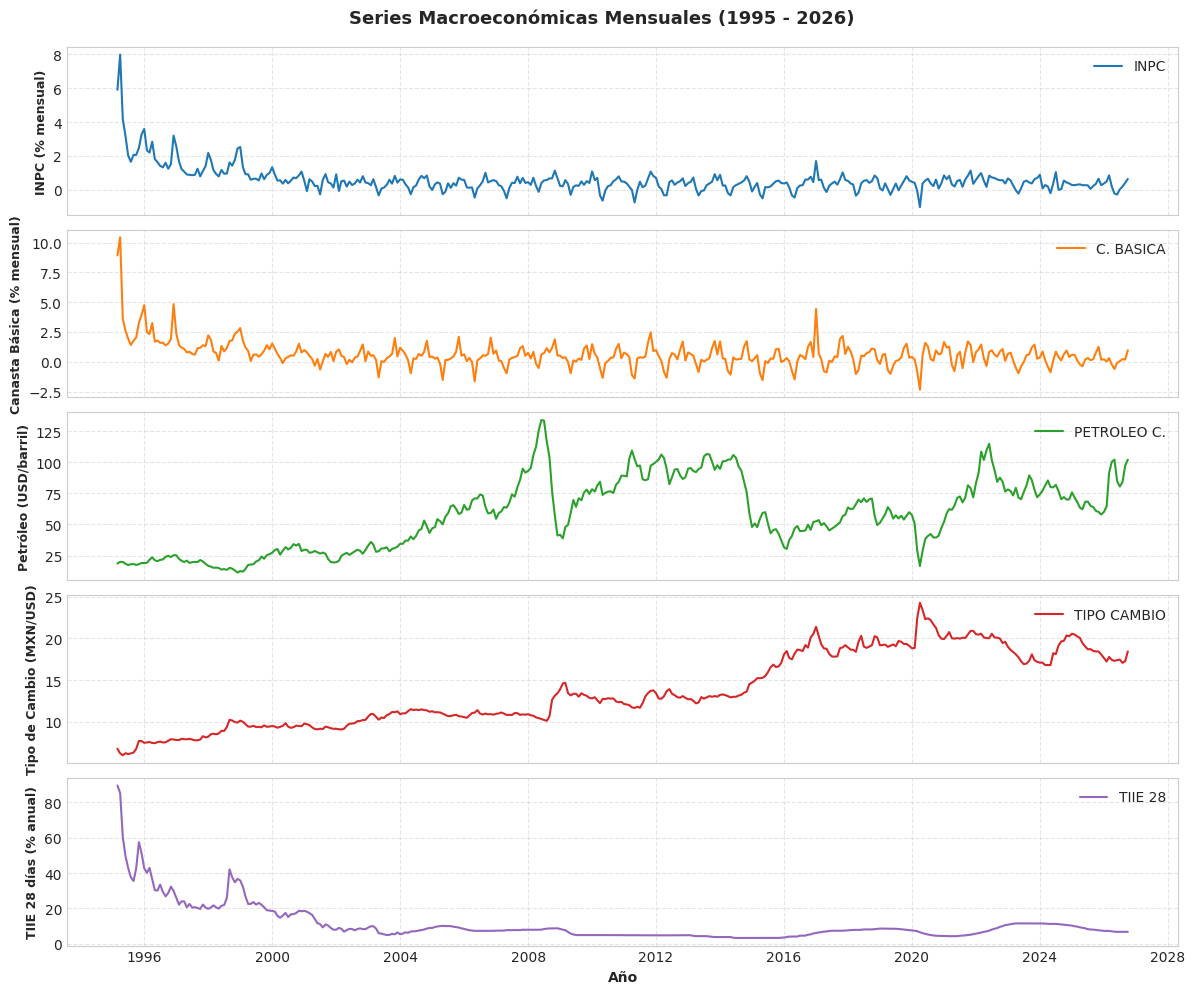

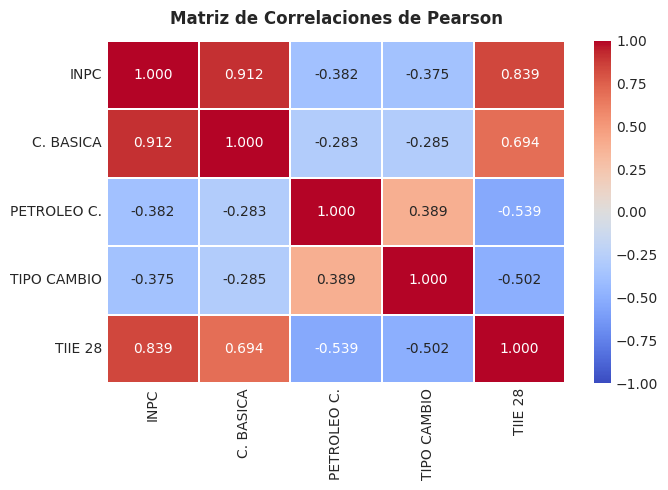

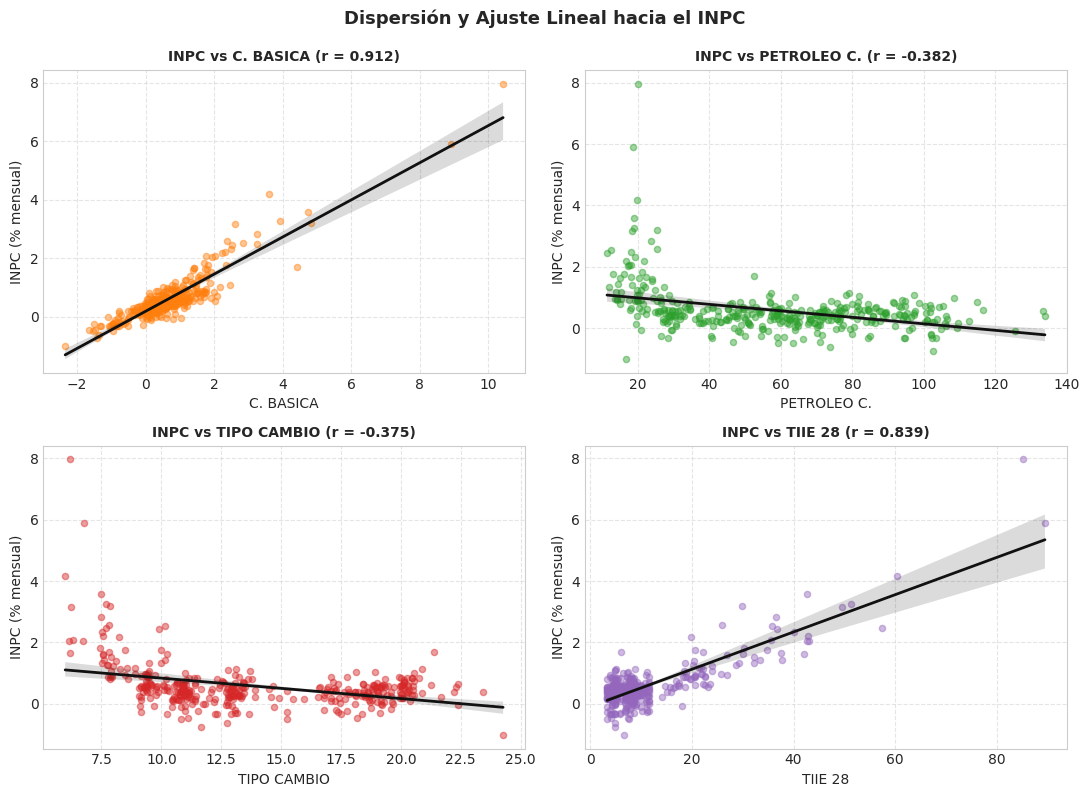

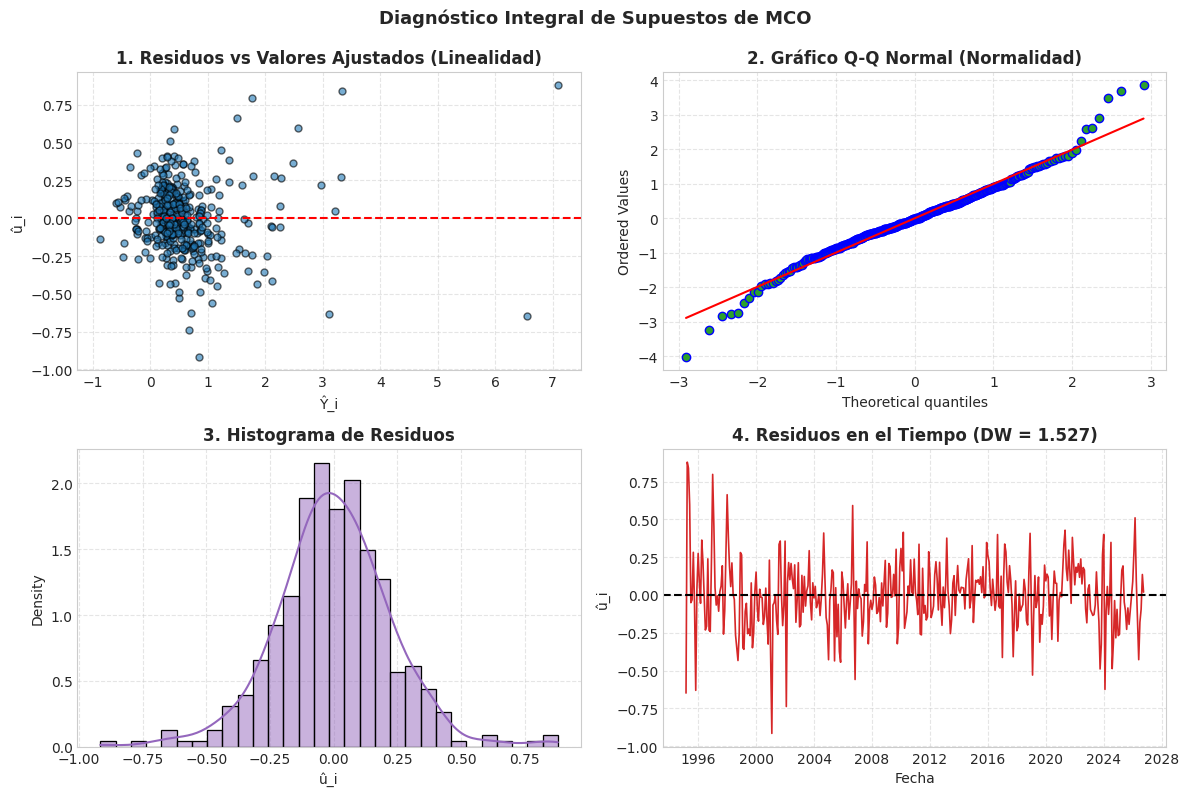

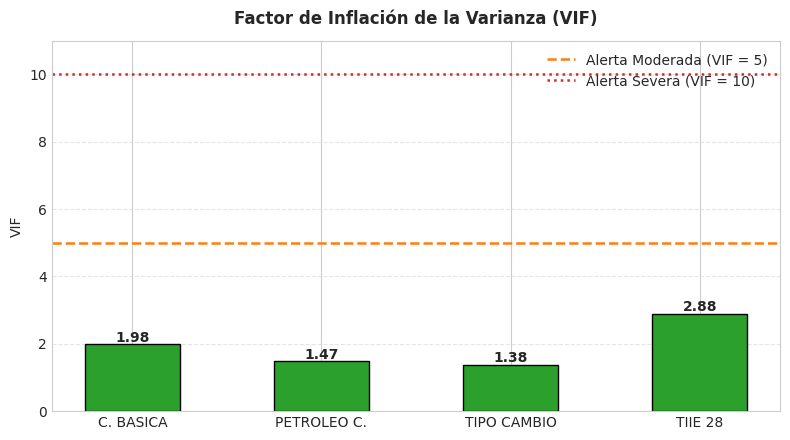

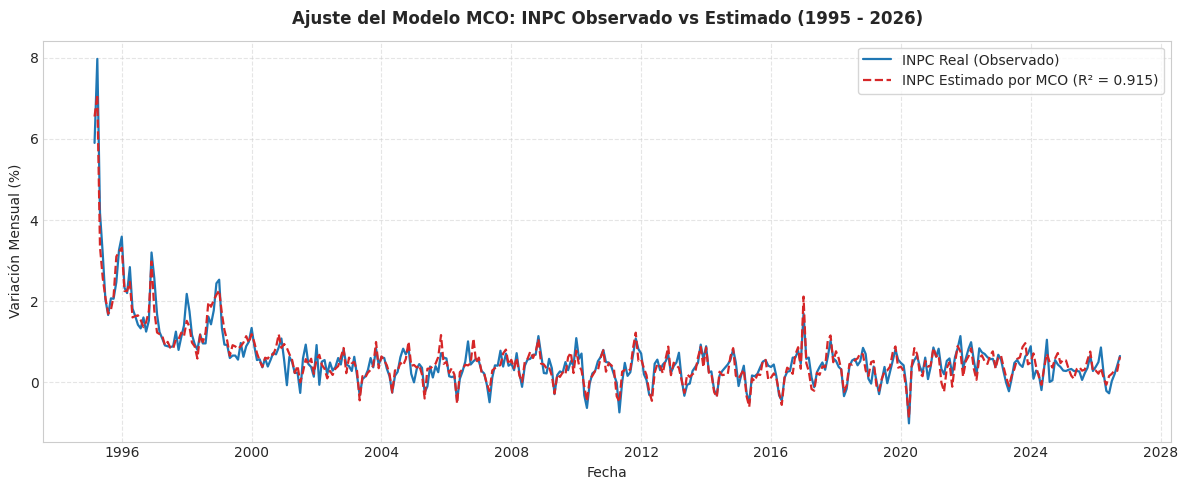


SÍNTESIS DE CONCLUSIONES PARA TU INFORME Y EXPOSICIÓN ORAL
1. BONDAD DE AJUSTE: El modelo explica el 91.45% de la variación de la inflación.
2. SIGNIFICANCIA: Canasta Básica (t = 29.75, p < 0.001) y TIIE 28 (t = 16.12, p < 0.001) son altamente significativas.
3. MULTICOLINEALIDAD: Aunque los VIFs individuales son bajos (< 3), el Número de Condición (341.6) y las correlaciones bivariadas revelan redundancia.
4. HALLAZGO CLAVE (SENSIBILIDAD): Al retirar la Canasta Básica en el Modelo 2, el Petróleo pasa a ser estadísticamente significativo (p = 0.010), demostrando que la Canasta Básica transmite indirectamente el efecto de los energéticos.
5. DIAGNÓSTICO DE RESIDUOS: Se detectó heterocedasticidad (Breusch-Pagan p < 0.001) y autocorrelación (DW = 1.527). Se recomienda presentar los resultados con errores estándar robustos HAC (Newey-West).


In [2]:
# ======================================================================================
# PROYECTO DE ECONOMETRÍA: DE LA REGRESIÓN LINEAL A LA MULTICOLINEALIDAD
# Modelo de Regresión MCO: Determinantes del INPC en México (1995 - 2026)
# ======================================================================================

# 1. INSTALACIÓN / IMPORTACIÓN DE LIBRERÍAS
import io
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan, het_white, acorr_breusch_godfrey
from statsmodels.stats.stattools import durbin_watson, jarque_bera

# Configuración visual para Google Colab
%matplotlib inline
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8
pd.set_option('display.max_columns', 15)
pd.set_option('display.width', 1000)

print("✓ Librerías cargadas con éxito.")

# ======================================================================================
# 2. CARGA DE LA BASE DE DATOS (AUTO-CONTENIDA)
# ======================================================================================
# Si tienes tu archivo CSV subido a Colab con el nombre 'datos_macro_mexico.csv', se usará.
# De lo contrario, se cargan automáticamente los datos compilados (1995 - 2026).

RAW_CSV_DATA = """FECHA MES,INPC,C. BASICA,PETROLEO C.,TIPO CAMBIO,TIIE 28
1995-03-01,5.9,8.92,18.59,6.7721590909090912,89.4825
1995-04-01,7.97,10.44,19.918333333333333,6.2063833333333331,85.22037499999999
1995-05-01,4.18,3.6,19.85235294117647,5.986071428571428,60.44625
1995-06-01,3.17,2.6,18.407619047619047,6.226881818181818,49.5
1995-07-01,2.04,1.95,17.334117647058825,6.1249904761904759,43
1995-08-01,1.66,1.41,18.027727272727272,6.2055217391304351,37.59854
1995-09-01,2.07,1.77,18.181111111111111,6.313405,35.480125
1995-10-01,2.06,2.04,17.447894736842105,6.7498272727272726,42.6075
1995-11-01,2.47,3.26,17.997894736842103,7.7055849999999992,57.43424
1995-12-01,3.26,3.93,19.014736842105265,7.680731578947368,51.356275
1996-01-01,3.59,4.75,18.937368421052632,7.476,42.657525
1996-02-01,2.33,2.5,19.168888888888887,7.524025,40.1055
1996-03-01,2.2,2.32,21.595555555555556,7.56874,42.929199999999994
1996-04-01,2.84,3.25,23.515789473684212,7.4616950000000006,36.613749999999996
1996-05-01,1.82,1.69,21.165454545454544,7.432604545454546,30.309545454545454
1996-06-01,1.63,1.78,20.43,7.56035,30.10525
1996-07-01,1.42,1.59,21.536875,7.6206173913043482,33.489782608695648
1996-08-01,1.33,1.61,21.837333333333333,7.511504545454545,29.357613636363634
1996-09-01,1.6,1.38,23.988666666666667,7.544045,26.822250000000004
1996-10-01,1.25,1.53,24.83,7.7262652173913047,28.684565217391306
1996-11-01,1.52,1.92,23.792307692307695,7.90602,32.284
1996-12-01,3.2,4.84,25.275000000000002,7.874075,29.919249999999998
1997-01-01,2.57,2.37,25.216666666666665,7.8269863636363644,25.959772727272728
1997-02-01,1.68,1.4,22.308333333333334,7.8003263157894738,22.106315789473683
1997-03-01,1.24,1.19,20.86470588235294,7.9647055555555557,23.950833333333335
1997-04-01,1.08,1.09,19.744444444444444,7.9074363636363643,23.980340909090909
1997-05-01,0.91,0.79,20.911538461538463,7.9006349999999994,20.64725
1997-06-01,0.89,0.85,19.083750000000002,7.9502047619047618,22.531666666666666
1997-07-01,0.87,0.65,19.658,7.8721521739130429,20.495217391304347
1997-08-01,0.89,0.6,19.893888888888888,7.7828476190476188,20.636785714285715
1997-09-01,1.25,1.14,19.781052631578948,7.78048,20.23425
1997-10-01,0.8,1.18,21.381176470588237,7.8602913043478262,19.697173913043478
1997-11-01,1.12,1.39,20.21153846153846,8.2689263157894732,22.171315789473685
1997-12-01,1.4,1.31,18.332727272727272,8.1218523809523813,20.481904761904762
1998-01-01,2.18,2.22,16.69625,8.21767619047619,19.740238095238094
1998-02-01,1.75,1.83,16.061176470588236,8.501352631578948,20.515789473684212
1998-03-01,1.17,0.87,15.125714285714285,8.5676045454545449,21.689318181818184
1998-04-01,0.94,0.73,15.353809523809524,8.496535,20.55175
1998-05-01,0.8,0.1,14.923529411764706,8.5933842105263167,19.895263157894735
1998-06-01,1.18,1.33,13.721818181818181,8.913127272727273,21.469545454545454
1998-07-01,0.96,0.88,14.129444444444443,8.8959739130434787,21.880434782608695
1998-08-01,0.96,1.15,13.47190476190476,9.3633,25.780714285714286
1998-09-01,1.62,1.74,15.089473684210526,10.230725,42.0395
1998-10-01,1.43,1.79,14.460909090909091,10.153563636363636,37.654318181818184
1998-11-01,1.77,2.35,13.025625,9.9681631578947378,34.775789473684213
1998-12-01,2.44,2.53,11.343888888888889,9.9056909090909091,36.691136363636367
1999-01-01,2.53,2.83,12.514736842105263,10.13513,35.7955
1999-02-01,1.34,1.77,12.033333333333333,9.9938842105263159,32.205263157894734
1999-03-01,0.93,1.22,14.152941176470588,9.7316,26.870434782608694
1999-04-01,0.92,0.92,17.428,9.41846,22.54025
1999-05-01,0.6,0.07,17.793333333333333,9.410515,22.52
1999-06-01,0.66,0.59,17.98,9.513881818181817,23.595227272727275
1999-07-01,0.66,0.62,20.240000000000002,9.3657045454545464,22.111136363636362
1999-08-01,0.56,0.42,21.1375,9.3965954545454551,23.1275
1999-09-01,0.97,0.63,24.184444444444445,9.335775,22.040375
1999-10-01,0.63,0.93,22.47,9.5667380952380956,20.631190476190476
1999-11-01,0.89,1.4,25.316111111111113,9.3988095238095237,19.005714285714287
1999-12-01,1,1.05,26.115555555555556,9.4248863636363627,18.745454545454546
2000-01-01,1.34,1.54,27.272941176470589,9.4877761904761915,18.551190476190477
2000-02-01,0.89,1.1,29.416842105263157,9.4251571428571435,18.151904761904763
2000-03-01,0.55,0.67,30.302,9.2875772727272743,15.769090909090909
2000-04-01,0.57,0.31,25.687058823529412,9.3903277777777774,14.736944444444443
2000-05-01,0.37,-0.11,28.892380952380954,9.5158095238095228,15.917142857142856
2000-06-01,0.59,0.29,31.779523809523809,9.8295409090909089,17.437954545454545
2000-07-01,0.39,0.4,29.944615384615386,9.4212,15.125714285714285
2000-08-01,0.55,0.54,31.234545454545454,9.27094347826087,16.615543478260872
2000-09-01,0.73,0.51,34.163888888888891,9.3540142857142854,16.770057142857144
2000-10-01,0.69,0.86,33.034,9.53135909090909,17.380168181818181
2000-11-01,0.86,1.52,34.335,9.5004,18.64225
2000-12-01,1.08,0.78,28.636470588235294,9.4661555555555541,18.394027777777779
2001-01-01,0.55,0.98,29.6021052631579,9.7765818181818176,18.619090909090911
2001-02-01,-0.07,0.79,29.609473684210528,9.70448947368421,18.11921052631579
2001-03-01,0.63,0.51,27.244545454545456,9.6005523809523812,17.280952380952378
2001-04-01,0.5,0.24,27.566470588235294,9.326810526315791,16.361052631578946
2001-05-01,0.23,-0.33,28.682,9.137172727272727,14.09125
2001-06-01,0.24,0.24,27.571578947368423,9.086728571428571,11.643928571428571
2001-07-01,-0.26,-0.65,26.568333333333335,9.1618181818181821,11.099545454545455
2001-08-01,0.59,0.05,27.373913043478261,9.1307521739130433,9.289782608695651
2001-09-01,0.93,0.66,26.466470588235296,9.4188549999999989,10.9475
2001-10-01,0.45,0.42,22.14952380952381,9.3449913043478254,10.338478260869564
2001-11-01,0.38,0.83,19.73125,9.2236380952380941,8.9
2001-12-01,0.14,0.05,19.452941176470588,9.156078947368421,7.9415789473684217
2002-01-01,0.92,0.85,19.624117647058824,9.1615954545454557,7.9675
2002-02-01,-0.06,1.04,20.76875,9.0998052631578954,8.9902631578947361
2002-03-01,0.51,0.51,24.71764705882353,9.0707444444444452,8.4702777777777776
2002-04-01,0.55,0.4,26.118571428571428,9.1628545454545449,6.8493181818181821
2002-05-01,0.2,-0.2,27.108095238095238,9.5191772727272728,7.727954545454546
2002-06-01,0.49,0.17,25.508,9.76519,8.41975
2002-07-01,0.29,-0.05,26.920499999999997,9.7807521739130436,8.3356521739130436
2002-08-01,0.38,0.35,28.385,9.8396090909090912,7.6136363636363633
2002-09-01,0.6,0.43830338,29.6635,10.07136,8.3730000000000011
2002-10-01,0.44,0.92,28.836521739130436,10.095030434782609,8.6719565217391317
2002-11-01,0.81,1.46,26.411666666666669,10.19745,8.33125
2002-12-01,0.44,0.05,29.516842105263162,10.224915,8.2555000000000014
2003-01-01,0.4,0.86,32.943888888888893,10.620313636363635,9.14340909090909
2003-02-01,0.28,0.5,35.9325,10.937163157894737,9.9051315789473673
2003-03-01,0.63,0.55,33.777,10.91239,9.961
2003-04-01,0.17,0.16,28.017000000000003,10.59174,8.58195
2003-05-01,-0.32,-1.31,28.452222222222222,10.251195238095239,5.9171428571428573
2003-06-01,0.08,0.05,30.631818181818179,10.504680952380951,5.7888095238095234
2003-07-01,0.14,-0.01,30.7325,10.45024347826087,5.2985869565217394
2003-08-01,0.3,0.3,31.643076923076926,10.781142857142857,4.9730952380952385
2003-09-01,0.6,0.45,28.359166666666667,10.926885714285714,5.0464285714285708
2003-10-01,0.37,0.66,30.353636363636362,11.174765217391302,5.5959217391304348
2003-11-01,0.83,1.99,30.9825,11.144978947368422,5.3544947368421054
2003-12-01,0.43,0.45,32.196923076923078,11.248585714285715,6.3977333333333331
2004-01-01,0.62,1.18,34.425,10.915071428571428,5.3569
2004-02-01,0.6,0.93,34.445833333333333,11.014173684210526,5.7914947368421048
2004-03-01,0.34,0.61,36.99,11.009413043478261,6.48505652173913
2004-04-01,0.15,0.13,36.994545454545452,11.27506,6.168305
2004-05-01,-0.25,-0.96,40.329285714285717,11.512428571428572,6.9476666666666675
2004-06-01,0.16,0.28,38.107058823529414,11.389390909090908,7.0247681818181826
2004-07-01,0.26,0.2453816,40.772777777777776,11.463590909090909,7.1126318181818187
2004-08-01,0.62,0.66,45.168421052631579,11.394177272727273,7.4999590909090905
2004-09-01,0.83,0.5,46.3975,11.486390476190476,7.7756666666666661
2004-10-01,0.69,0.83,53.134117647058822,11.398319047619047,8.0454857142857144
2004-11-01,0.85,1.76,48.548947368421047,11.368145454545454,8.5979590909090913
2004-12-01,0.21,0.4,43.149523809523807,11.204108695652174,8.9306217391304354
2005-01-01,0,0.44,46.856842105263155,11.260738095238096,8.9683333333333337
2005-02-01,0.33,0.26,47.805333333333337,11.136725,9.467
2005-03-01,0.45,0.36,54.2557894736842,11.142700000000001,9.777
2005-04-01,0.36,-0.17,52.611875,11.116295238095239,10.014285714285714
2005-05-01,-0.25,-1.52,50.02,10.973259090909091,10.122272727272728
2005-06-01,-0.1,0.15,56.279444444444444,10.822777272727272,10.01
2005-07-01,0.39,0.16,58.935625,10.678142857142857,10.014761904761905
2005-08-01,0.12,0.28,64.6265,10.688217391304349,9.9843478260869567
2005-09-01,0.4,0.45,65.478235294117638,10.777542857142857,9.649285714285714
2005-10-01,0.25,0.84,62.468125,10.832442857142857,9.4084523809523812
2005-11-01,0.72,2.09,58.405625,10.668454545454544,9.1675
2005-12-01,0.61,0.51,59.37133333333334,10.629452380952381,8.7217857142857138
2006-01-01,0.59,0.63,65.640555555555551,10.547004545454545,8.4120454545454546
2006-02-01,0.15,0.05,61.777647058823533,10.48327894736842,7.9682894736842114
2006-03-01,0.13,0.33,62.396315789473682,10.746763636363637,7.6771590909090914
2006-04-01,0.15,-0.03,69.290588235294123,11.042122222222222,7.5147222222222219
2006-05-01,-0.45,-1.64,70.894,11.092281818181819,7.3197727272727269
2006-06-01,0.09,0.12,70.898571428571429,11.391263636363636,7.3334090909090914
2006-07-01,0.27,0.28,74.0825,10.985785714285715,7.3116666666666656
2006-08-01,0.51,0.54,73.193181818181813,10.871965217391304,7.3007782608695653
2006-09-01,1.01,0.51,64.068235294117656,10.985309523809523,7.3083857142857145
2006-10-01,0.44,0.64,58.893181818181823,10.897145454545454,7.313331818181819
2006-11-01,0.52,2.02,59.151176470588233,10.91773,7.302225
2006-12-01,0.58,0.67,61.959,10.847866666666667,7.3381277777777774
2007-01-01,0.52,0.95,54.530999999999992,10.952863636363636,7.4050681818181809
2007-02-01,0.28,0.1,59.225882352941177,10.999799999999999,7.4566421052631577
2007-03-01,0.22,0.07,60.441818181818185,11.113861904761904,7.4553904761904759
2007-04-01,-0.06,-0.53,63.98263157894737,10.980584210526317,7.4666473684210528
2007-05-01,-0.49,-0.96,63.454545454545453,10.816690909090909,7.6997772727272737
2007-06-01,0.12,0.2,67.489047619047625,10.834976190476191,7.7035523809523809
2007-07-01,0.42,0.32,74.117619047619044,10.810931818181817,7.7041272727272734
2007-08-01,0.41,0.4,72.356086956521736,11.045634782608696,7.7087608695652179
2007-09-01,0.78,0.49,79.914736842105256,11.031495,7.7040099999999994
2007-10-01,0.39,1.13,85.7986956521739,10.823143478260869,7.7327173913043472
2007-11-01,0.71,1.32,94.772380952380956,10.88664,7.9337649999999993
2007-12-01,0.41,0.5,91.687,10.848394736842105,7.9325578947368429
2008-01-01,0.46,0.75,92.970476190476191,10.910013636363637,7.9259863636363637
2008-02-01,0.3,0.28,95.386,10.76653,7.9283199999999994
2008-03-01,0.72,0.84,105.454,10.731311111111111,7.9312055555555547
2008-04-01,0.23,-0.16,112.58045454545454,10.51535,7.9355227272727271
2008-05-01,-0.11,-0.52,125.39761904761905,10.435152380952381,7.9327000000000005
2008-06-01,0.41,0.62,133.88,10.329209523809524,8.00232380952381
2008-07-01,0.56,0.73,133.37090909090909,10.215517391304347,8.2828695652173909
2008-08-01,0.58,1.14,116.66619047619047,10.109509523809525,8.5576190476190472
2008-09-01,0.68,0.79,104.11428571428571,10.643685714285715,8.6603571428571424
2008-10-01,0.68,1.16,76.6086956521739,12.631386956521739,8.6764130434782611
2008-11-01,1.14,1.88,57.309473684210531,13.113952631578947,8.7339473684210525
2008-12-01,0.69,0.53,41.121818181818185,13.422633333333332,8.73967619047619
2009-01-01,0.23,0.51,41.71,13.892114285714285,8.4147666666666669
2009-02-01,0.22,0.31,38.806111111111107,14.596642105263159,7.936594736842105
2009-03-01,0.58,0.39,47.939090909090915,14.66952857142857,7.6427380952380952
2009-04-01,0.35,-0.02,49.646666666666661,13.436744999999998,6.677365
2009-05-01,-0.29,-0.96,59.028499999999994,13.162085,5.7799549999999993
2009-06-01,0.18,0.12,69.640909090909091,13.341795454545455,5.2618454545454547
2009-07-01,0.27,0.02,64.120952380952374,13.365408695652174,4.9172
2009-08-01,0.24,0.27,71.044761904761913,13.008033333333334,4.8894095238095234
2009-09-01,0.5,0.16,69.408095238095228,13.421152380952382,4.9111047619047623
2009-10-01,0.3,1.12,75.715454545454548,13.22565909090909,4.925272727272727
2009-11-01,0.52,1.37,77.99,13.109368421052631,4.9311684210526314
2009-12-01,0.41,0.23,74.47,12.863090909090909,4.9306136363636366
2010-01-01,1.09,1.48,78.32578947368421,12.801855,4.91003
2010-02-01,0.58,0.66,76.387368421052628,12.942415789473685,4.9173421052631578
2010-03-01,0.71,0.37,81.203478260869574,12.573659090909091,4.9231818181818179
2010-04-01,-0.32,-0.53,84.292857142857144,12.23015,4.9370150000000006
2010-05-01,-0.63,-1.35,73.7435,12.742823809523811,4.9435238095238088
2010-06-01,-0.03,-0.11,75.3359090909091,12.719331818181816,4.9376545454545457
2010-07-01,0.22,0.07,76.319523809523815,12.818872727272726,4.9192909090909094
2010-08-01,0.28,0.34,76.599090909090918,12.769463636363637,4.9042090909090907
2010-09-01,0.52,0.36,75.241904761904763,12.799745,4.9006300000000005
2010-10-01,0.62,1.07,81.892857142857139,12.437380952380952,4.8707904761904759
2010-11-01,0.8,1.5,84.252857142857138,12.33906,4.8651649999999993
2010-12-01,0.5,0.29,89.145909090909086,12.388491304347825,4.88745652173913
2011-01-01,0.49,0.77,89.1705,12.125847619047619,4.8589904761904759
2011-02-01,0.38,0.65,88.578421052631583,12.070321052631579,4.8410631578947365
2011-03-01,0.19,0.41,102.82545454545453,11.999172727272729,4.8407681818181816
2011-04-01,-0.01,-1.11,109.36692307692307,11.718399999999999,4.8460842105263158
2011-05-01,-0.74,-1.41,102.5725,11.653295454545455,4.8471545454545453
2011-06-01,0,0.29,96.716666666666669,11.806018181818182,4.8454227272727275
2011-07-01,0.48,0.38,97.309999999999988,11.672557142857142,4.8213428571428567
2011-08-01,0.16,0.34,86.333043478260876,12.231913043478261,4.808
2011-09-01,0.25,0.43,85.515238095238089,13.044519047619049,4.7775952380952376
2011-10-01,0.67,1.6,86.322380952380954,13.435004761904763,4.7942666666666662
2011-11-01,1.08,2.47,97.160476190476189,13.69929,4.799825
2011-12-01,0.82,0.9,98.562857142857155,13.768880952380952,4.7980619047619042
2012-01-01,0.71,0.98,100.2735,13.417777272727273,4.7873454545454548
2012-02-01,0.2,0.48,102.204,12.78306,4.78423
2012-03-01,0.06,0.09,106.15772727272729,12.756699999999999,4.7692523809523815
2012-04-01,-0.31,-0.85,103.321,13.069673684210526,4.743826315789474
2012-05-01,-0.32,-1.34,94.654545454545456,13.663381818181819,4.7602090909090906
2012-06-01,0.46,0.25,82.303333333333327,13.91920476190476,4.763290476190476
2012-07-01,0.56,0.73,87.8952380952381,13.366081818181819,4.7778909090909085
2012-08-01,0.3,0.6,94.131304347826088,13.184521739130433,4.7881652173913043
2012-09-01,0.44,0.2,94.513684210526321,12.939435,4.802305
2012-10-01,0.51,0.99,89.4913043478261,12.891,4.8169739130434781
2012-11-01,0.68,1.7,86.531428571428577,13.0746,4.842805
2012-12-01,0.23,0.1,87.8595,12.87047894736842,4.8420894736842106
2013-01-01,0.4,0.79,94.756666666666675,12.699,4.8413227272727273
2013-02-01,0.49,0.65,95.308947368421045,12.722884210526317,4.82311052631579
2013-03-01,0.73,0.52,92.9385,12.524722222222222,4.4823666666666675
2013-04-01,0.07,-0.17,92.021363636363631,12.20504090909091,4.3345636363636366
2013-05-01,-0.33,-0.86,94.472857142857151,12.311486363636364,4.3164545454545458
2013-06-01,-0.06,0.17,95.772500000000008,12.959575000000001,4.303635
2013-07-01,-0.03,0.02,104.67090909090908,12.76585652173913,4.3183043478260865
2013-08-01,0.28,0.17,106.57272727272726,12.91780909090909,4.30615
2013-09-01,0.38,0.3,106.2895,13.075905,4.1049050000000005
2013-10-01,0.48,1.14,100.53826086956522,12.999217391304349,3.9768565217391303
2013-11-01,0.93,1.75,93.864,13.079555,3.78953
2013-12-01,0.57,0.61,97.590499999999992,13.00755,3.7903350000000002
2014-01-01,0.89,1.71,94.617142857142852,13.223022727272728,3.7819727272727275
2014-02-01,0.25,0.29,100.81736842105263,13.280778947368422,3.787052631578947
2014-03-01,0.27,0.25,100.80380952380953,13.195085,3.8012950000000005
2014-04-01,-0.19,-0.79,102.06904761904761,13.070834999999999,3.8064349999999996
2014-05-01,-0.32,-1.08,102.17714285714285,12.924733333333332,3.8025095238095239
2014-06-01,0.17,0.37,105.79428571428571,12.995761904761904,3.4286476190476187
2014-07-01,0.28,0.19,103.58863636363638,12.990443478260868,3.2975086956521742
2014-08-01,0.36,0.22,96.53619047619047,13.140638095238094,3.2985523809523807
2014-09-01,0.44,0.25,93.211904761904762,13.235204761904763,3.2893142857142856
2014-10-01,0.55,1.25,84.673809523809524,13.476252173913043,3.2919130434782606
2014-11-01,0.81,1.73,75.78947368421052,13.621605263157894,3.287321052631579
2014-12-01,0.49,0.2,59.069500000000005,14.512895238095238,3.2997238095238095
2015-01-01,-0.09,0.05,47.915,14.692585714285716,3.30162380952381
2015-02-01,0.19,0.32,50.788235294117648,14.921342105263157,3.2970894736842107
2015-03-01,0.41,0.55,47.823636363636361,15.228338095238096,3.3029095238095243
2015-04-01,-0.26,-0.95,54.452857142857141,15.22618,3.2965150000000003
2015-05-01,-0.5,-1.54,59.265,15.26447,3.30117
2015-06-01,0.17,0.05,59.819545454545455,15.483036363636364,3.3046636363636366
2015-07-01,0.15,-0.1,50.900909090909089,15.939582608695654,3.3035217391304346
2015-08-01,0.21,0.28,42.867619047619051,16.536757142857144,3.3161666666666667
2015-09-01,0.37,0.25,45.479523809523812,16.857761904761908,3.3343000000000003
2015-10-01,0.51,1.04,46.223636363636359,16.564004545454544,3.3050181818181814
2015-11-01,0.55,1.1,42.4435,16.635689473684209,3.3163
2015-12-01,0.41,-0.02,37.188636363636363,17.066622727272726,3.4151272727272728
2016-01-01,0.38,0.1,31.683157894736844,18.072775,3.55659
2016-02-01,0.44,0.32,30.323,18.4731,3.75062
2016-03-01,0.15,0.04,37.546363636363637,17.649045,4.062685
2016-04-01,-0.32,-0.78,40.7552380952381,17.48767619047619,4.0642333333333331
2016-05-01,-0.45,-1.48,46.712380952380954,18.154186363636367,4.0750227272727271
2016-06-01,0.11,0.02,48.757272727272728,18.652968181818181,4.1012181818181821
2016-07-01,0.26,0.57,44.6515,18.601442857142857,4.5597857142857139
2016-08-01,0.28,0.45,44.724347826086962,18.474865217391304,4.5906304347826081
2016-09-01,0.61,0.22,45.182380952380953,19.192409523809523,4.611019047619048
2016-10-01,0.61,1.26,49.775238095238095,18.892414285714285,5.1085619047619044
2016-11-01,0.78,1.66,45.660952380952381,20.118465,5.336275
2016-12-01,0.46,0.41,51.9704761904762,20.520576190476191,5.8390095238095245
2017-01-01,1.7,4.43,52.504,21.385272727272728,6.1279954545454549
2017-02-01,0.58,0.69,53.468421052631577,20.290536842105261,6.4387631578947371
2017-03-01,0.61,0.22,49.32782608695652,19.301027272727271,6.6279545454545454
2017-04-01,0.12,-0.79,51.060526315789474,18.787483333333331,6.8661222222222218
2017-05-01,-0.12,-0.89,48.476363636363637,18.755663636363636,6.9778818181818174
2017-06-01,0.25,0.1,45.177727272727275,18.132613636363637,7.2149
2017-07-01,0.38,-0.02,46.630526315789474,17.828338095238095,7.3663619047619049
2017-08-01,0.49,0.45,48.036956521739128,17.807030434782607,7.3755913043478261
2017-09-01,0.31,0.4,49.822,17.835652380952382,7.376442857142858
2017-10-01,0.63,1.91,51.577727272727273,18.816095454545454,7.3789772727272727
2017-11-01,1.03,2.17,56.638571428571431,18.915785,7.37982
2017-12-01,0.59,0.66,57.8815,19.181221052631578,7.5052473684210534
2018-01-01,0.53,1.26,63.698571428571434,18.90739090909091,7.6360590909090913
2018-02-01,0.38,0.85,62.229473684210518,18.644936842105263,7.7819157894736843
2018-03-01,0.32,0.22,62.724761904761905,18.630842105263156,7.8341368421052637
2018-04-01,-0.34,-1.03,66.253809523809522,18.387185714285714,7.8404619047619049
2018-05-01,-0.16,-0.68,69.978181818181824,19.590995454545453,7.8509590909090914
2018-06-01,0.39,0.52,67.873333333333335,20.3032,7.928114285714285
2018-07-01,0.54,0.47,70.981428571428566,19.009518181818184,8.1042272727272735
2018-08-01,0.58,0.72,68.055652173913046,18.857508695652172,8.1060086956521733
2018-09-01,0.42,0.82,70.2321052631579,19.015430000000002,8.114085
2018-10-01,0.52,1.11,70.748695652173907,19.185865217391303,8.1179173913043474
2018-11-01,0.85,1.05,56.963499999999996,20.26117,8.24542
2018-12-01,0.7,0.14,49.522777777777776,20.111178947368419,8.4103105263157882
2019-01-01,0.09,-0.18,51.375714285714288,19.1651,8.59225909090909
2019-02-01,-0.03,0.6,54.95473684210527,19.204878947368421,8.5617
2019-03-01,0.39,0.66,58.151428571428575,19.24774,8.5190200000000011
2019-04-01,0.05,-0.72,63.862380952380946,18.986349999999998,8.498155
2019-05-01,-0.29,-1.01,60.826818181818183,19.119654545454548,8.5065545454545468
2019-06-01,0.06,-0.32,54.657500000000006,19.27447,8.507475
2019-07-01,0.38,0.06,57.358095238095238,19.053395652173911,8.4752217391304345
2019-08-01,-0.02,0.14,54.80590909090909,19.685040909090908,8.36980909090909
2019-09-01,0.26,0.37,56.947,19.586505,8.1971099999999986
2019-10-01,0.54,1.17,53.963043478260872,19.324182608695654,7.9986043478260873
2019-11-01,0.81,1.52,57.048947368421054,19.332475,7.872655
2019-12-01,0.56,0.34,59.81666666666667,19.107085,7.6965249999999994
2020-01-01,0.48,0.41,57.519047619047626,18.804018181818183,7.5302818181818187
2020-02-01,0.42,0.19,50.542631578947372,18.844321052631578,7.3905315789473676
2020-03-01,-0.05,-0.8,29.207727272727276,22.3784,7.1006761904761913
2020-04-01,-1.01,-2.35,16.547619047619047,24.26584,6.5377300000000007
2020-05-01,0.38,0.52,28.5625,23.42302,5.99545
2020-06-01,0.55,1.59,38.307272727272725,22.29895909090909,5.6487045454545459
2020-07-01,0.66,1.29,40.710454545454546,22.403282608695651,5.2314695652173917
2020-08-01,0.39,0.24,42.339047619047619,22.207161904761907,4.9674190476190478
2020-09-01,0.23,0.08,39.63428571428571,21.680980952380953,4.7202857142857146
2020-10-01,0.61,0.96,39.395909090909093,21.270500000000002,4.5324590909090912
2020-11-01,0.08,0.63,40.937368421052632,20.381915789473684,4.4986105263157894
2020-12-01,0.38,0.69,47.025,19.965077272727271,4.485686363636364
2021-01-01,0.86,1.66,52.008421052631576,19.921475,4.468395
2021-02-01,0.63,1.2,59.046315789473688,20.309731578947368,4.3628631578947372
2021-03-01,0.83,1.28,62.333043478260876,20.75545,4.2833318181818179
2021-04-01,0.33,-0.26,61.716666666666661,20.015285,4.28445
2021-05-01,0.2,-0.78,65.1695,19.963128571428573,4.2851238095238093
2021-06-01,0.53,0.54,71.378181818181815,20.03006818181818,4.31705
2021-07-01,0.59,0.84,72.4852380952381,19.970109090909091,4.5193227272727272
2021-08-01,0.19,-0.53,67.730454545454549,20.076136363636365,4.6454909090909089
2021-09-01,0.62,0.78,71.646190476190469,20.048690476190476,4.74612380952381
2021-10-01,0.84,1.71,81.476666666666659,20.462557142857143,4.9750904761904762
2021-11-01,1.14,1.39,79.147500000000008,20.900425,5.1255450000000007
2021-12-01,0.36,-0.03,71.711818181818188,20.891843478260871,5.4425739130434776
2022-01-01,0.59,0.81,83.222000000000008,20.497771428571429,5.7237666666666671
2022-02-01,0.83,1.06,91.641052631578944,20.449521052631582,6.0226578947368417
2022-03-01,0.99,1.46,108.50260869565217,20.556209090909093,6.3347181818181815
2022-04-01,0.54,0.29,101.7775,20.108805263157894,6.7318263157894735
2022-05-01,0.18,-0.35,109.55238095238094,20.030527272727273,7.0137909090909094
2022-06-01,0.84,0.84,114.83714285714285,20.023736363636363,7.421636363636364
2022-07-01,0.74,0.96,101.619,20.546723809523808,8.037290476190476
2022-08-01,0.7,0.6,93.665217391304353,20.120930434782608,8.4980478260869567
2022-09-01,0.62,0.44,84.258095238095237,20.07502380952381,8.8910952380952377
2022-10-01,0.57,0.86,87.5547619047619,19.984542857142859,9.5625380952380947
2022-11-01,0.58,1.07,84.370476190476182,19.444915,9.998965
2022-12-01,0.38,0.08,76.437142857142859,19.592961904761903,10.525376190476191
2023-01-01,0.68,0.68,78.123,18.986336363636365,10.780886363636363
2023-02-01,0.56,0.76,76.832631578947371,18.598568421052629,11.101473684210527
2023-03-01,0.27,0.13,73.277826086956523,18.374904545454545,11.336627272727272
2023-04-01,-0.02,-0.5,79.446315789473687,18.085494444444446,11.528288888888888
2023-05-01,-0.22,-0.96,71.578181818181818,17.7373,11.535522727272728
2023-06-01,0.1,-0.37,70.248095238095246,17.241204545454544,11.501090909090909
2023-07-01,0.48,-0.01,76.0695,16.904938095238094,11.500861904761905
2023-08-01,0.55,0.55,81.386086956521737,16.976643478260872,11.499778260869563
2023-09-01,0.44,0.63,89.425,17.307690476190476,11.503252380952381
2023-10-01,0.38,1.21,85.639523809523808,18.082331818181817,11.503368181818182
2023-11-01,0.64,1.44,77.685,17.376695,11.505175
2023-12-01,0.71,0.26,71.9,17.185989473684209,11.504194736842106
2024-01-01,0.89,0.36,74.152380952380952,17.08731818181818,11.500872727272727
2024-02-01,0.09,0.87,77.249,17.089775,11.495745
2024-03-01,0.29,0.14,81.277999999999992,16.791788888888888,11.441177777777778
2024-04-01,0.2,-0.42,85.347272727272738,16.810440909090911,11.2467
2024-05-01,-0.19,-0.88,80.024545454545446,16.793563636363636,11.239631818181818
2024-06-01,0.38,0.11,79.767368421052623,18.21737,11.244945
2024-07-01,1.05,0.85,81.800454545454542,18.111691304347826,11.245565217391302
2024-08-01,0.01,0.4,76.683181818181822,19.151481818181818,11.08025
2024-09-01,0.05,0.11,70.236,19.631629999999998,10.950050000000001
2024-10-01,0.55,0.63,71.985,19.706181818181818,10.73550909090909
2024-11-01,0.44,0.95,69.95,20.34549,10.605735
2024-12-01,0.38,0.4,70.118095238095236,20.266055,10.38072
2025-01-01,0.29,0.59,75.742499999999993,20.54901818181818,10.282522727272728
2025-02-01,0.28,0.58,71.533157894736846,20.457136842105264,9.8788842105263157
2025-03-01,0.31,0.14,68.239047619047625,20.241745,9.73917
2025-04-01,0.33,-0.22,63.536666666666669,20.056355,9.27798
2025-05-01,0.28,-0.38,62.167619047619048,19.435495238095239,9.0499380952380957
2025-06-01,0.28,0.18,68.169000000000011,19.029980952380953,8.7360047619047609
2025-07-01,0.27,0.32,68.390909090909091,18.690930434782608,8.2557347826086964
2025-08-01,0.06,0.14,64.864285714285714,18.706328571428571,8.08585238095238
2025-09-01,0.23,0.21,63.959047619047624,18.499009523809523,8.0178380952380959
2025-10-01,0.36,0.77,60.894545454545458,18.429582608695654,7.8122782608695651
2025-11-01,0.66,1.25,60.062222222222218,18.418484210526316,7.6097526315789468
2025-12-01,0.28,0.17,57.972272727272724,18.07389523809524,7.4709571428571424
2026-01-01,0.38,0.21,60.037,17.6449,7.30197619047619
2026-02-01,0.5,0.03,64.50842105263159,17.222768421052631,7.2864526315789471
2026-03-01,0.86,0.31,91.38363636363637,17.769214285714288,7.241652380952381
2026-04-01,0.2,-0.24,100.31666666666668,17.41873,7.0216949999999994
2026-05-01,-0.21,-0.6,102.134,17.30336,6.828245
2026-06-01,-0.27,-0.08,84.807142857142864,17.381913636363638,6.728918181818182
2026-07-01,0.03,0.04,80.456363636363633,17.460739130434781,6.7593782608695649
2026-08-01,0.2,0.23,83.897619047619045,17.066371428571429,6.7558809523809531
2026-09-01,0.42,0.19,97.308095238095234,17.264019047619048,6.7716523809523812
2026-10-01,0.65,0.97,102.06636363636363,18.433963636363636,6.7723227272727264"""

if os.path.exists('datos_macro_mexico.csv'):
    df = pd.read_csv('datos_macro_mexico.csv')
    print("✓ Archivo 'datos_macro_mexico.csv' detectado en el entorno.")
else:
    df = pd.read_csv(io.StringIO(RAW_CSV_DATA.strip()))
    df.to_csv('datos_macro_mexico.csv', index=False)
    print("✓ Datos compilados guardados como 'datos_macro_mexico.csv'.")

df.columns = [c.strip() for c in df.columns]
df['FECHA MES'] = pd.to_datetime(df['FECHA MES'])
df = df.sort_values('FECHA MES').reset_index(drop=True)
print(f"Dimensiones de la muestra: {df.shape[0]} observaciones mensuales x {df.shape[1]} columnas.")

# ======================================================================================
# 3. ESTADÍSTICAS DESCRIPTIVAS
# ======================================================================================
var_names = ['INPC', 'C. BASICA', 'PETROLEO C.', 'TIPO CAMBIO', 'TIIE 28']
desc = df[var_names].describe(percentiles=[0.25, 0.50, 0.75]).T
desc['IQR'] = desc['75%'] - desc['25%']
desc['Asimetría'] = df[var_names].skew()
desc['Curtosis'] = df[var_names].kurtosis()
desc['CV (%)'] = (desc['std'] / desc['mean'].abs()) * 100

columnas_orden = ['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max', 'IQR', 'Asimetría', 'Curtosis', 'CV (%)']
desc = desc[columnas_orden]
desc.columns = ['N', 'Media', 'Desv. Est.', 'Mínimo', 'Q1 (25%)', 'Mediana', 'Q3 (75%)', 'Máximo', 'IQR', 'Asimetría', 'Curtosis', 'CV (%)']

print("\n" + "="*80)
print("TABLA 1: ESTADÍSTICAS DESCRIPTIVAS COMPLETAS (1995 - 2026)")
print("="*80)
display(desc.round(4))

# ======================================================================================
# 4. ESTIMACIÓN MCO (MODELO PRINCIPAL)
# ======================================================================================
y = df['INPC']
X = df[['C. BASICA', 'PETROLEO C.', 'TIPO CAMBIO', 'TIIE 28']]
X_const = sm.add_constant(X)

# Estimación clásica por MCO
modelo_mco = sm.OLS(y, X_const).fit()

# Estimación robusta a Heterocedasticidad y Autocorrelación (Newey-West HAC)
modelo_hac = sm.OLS(y, X_const).fit(cov_type='HAC', cov_kwds={'maxlags': 4})

print("\n" + "="*80)
print("RESUMEN DE ESTIMACIÓN MCO (STATSMODELS)")
print("="*80)
print(modelo_mco.summary())

# Tabla limpia de coeficientes e intervalos de confianza
conf_int = modelo_mco.conf_int()
tabla_coef = pd.DataFrame({
    'Coeficiente (β)': modelo_mco.params,
    'Error Estándar (SE)': modelo_mco.bse,
    'Estadístico t': modelo_mco.tvalues,
    'p-valor': modelo_mco.pvalues,
    'IC 95% Inferior': conf_int[0],
    'IC 95% Superior': conf_int[1],
    'Significancia (α=0.05)': [
        '*** (p < 0.001)' if p < 0.001 else ('** (p < 0.01)' if p < 0.01 else ('* (p < 0.05)' if p < 0.05 else 'No significativo'))
        for p in modelo_mco.pvalues
    ]
})

print("\n" + "="*80)
print("TABLA 2: COEFICIENTES, ERRORES ESTÁNDAR Y PRUEBAS t INDIVIDUALES")
print("="*80)
display(tabla_coef.round(5))

# ======================================================================================
# 5. DIAGNÓSTICO DE MULTICOLINEALIDAD (VIF Y CONDICIÓN)
# ======================================================================================
cols_regresores = ['C. BASICA', 'PETROLEO C.', 'TIPO CAMBIO', 'TIIE 28']
vif_list = []

for col in cols_regresores:
    y_aux = X_const[col]
    X_aux = X_const[[c for c in cols_regresores if c != col]]
    aux_model = sm.OLS(y_aux, sm.add_constant(X_aux)).fit()
    r2_aux = aux_model.rsquared
    vif_val = 1.0 / (1.0 - r2_aux) if (1.0 - r2_aux) > 1e-10 else np.inf
    tolerancia = 1.0 / vif_val
    estado = "Bajo (< 5)" if vif_val < 5 else ("Moderado (5-10)" if vif_val < 10 else "Crítico (>= 10)")

    vif_list.append({
        'Regresor': col,
        'R² Auxiliar (R_j²)': r2_aux,
        'Tolerancia (1 - R_j²)': tolerancia,
        'VIF': vif_val,
        'Nivel de Alerta': estado
    })

df_vif = pd.DataFrame(vif_list)
print("\n" + "="*80)
print("TABLA 3: FACTORES DE INFLACIÓN DE VARIANZA (VIF) Y TOLERANCIA")
print("="*80)
display(df_vif.round(4))
print(f"\nNúmero de Condición de la matriz de diseño (Condition Number): {modelo_mco.condition_number:.2f}")

# ======================================================================================
# 6. DIAGNÓSTICO DE RESIDUOS (SUPUESTOS DE GAUSS-MARKOV)
# ======================================================================================
residuos = modelo_mco.resid

# Normalidad
jb_stat, jb_pval, _, _ = jarque_bera(residuos)
shapiro_stat, shapiro_pval = stats.shapiro(residuos)

# Homocedasticidad
bp_lm_stat, bp_lm_pval, _, _ = het_breuschpagan(residuos, X_const)
try:
    white_lm_stat, white_lm_pval, _, _ = het_white(residuos, X_const)
except Exception:
    white_lm_stat, white_lm_pval = np.nan, np.nan

# Autocorrelación
dw_stat = durbin_watson(residuos)
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    bg_lm_stat, bg_lm_pval, _, _ = acorr_breusch_godfrey(modelo_mco, nlags=1)
    bg4_lm_stat, bg4_lm_pval, _, _ = acorr_breusch_godfrey(modelo_mco, nlags=4)

df_diagnosticos = pd.DataFrame([
    {'Prueba': 'Normalidad: Jarque-Bera', 'Estadístico': jb_stat, 'p-valor': jb_pval, 'H0': 'Residuos Normales', 'Decisión (α=0.05)': 'Rechaza H0 (No normal)' if jb_pval < 0.05 else 'Normal'},
    {'Prueba': 'Normalidad: Shapiro-Wilk', 'Estadístico': shapiro_stat, 'p-valor': shapiro_pval, 'H0': 'Residuos Normales', 'Decisión (α=0.05)': 'Rechaza H0 (No normal)' if shapiro_pval < 0.05 else 'Normal'},
    {'Prueba': 'Homocedasticidad: Breusch-Pagan', 'Estadístico': bp_lm_stat, 'p-valor': bp_lm_pval, 'H0': 'Varianza Constante', 'Decisión (α=0.05)': 'Heterocedasticidad detectada' if bp_lm_pval < 0.05 else 'Homocedástico'},
    {'Prueba': 'Homocedasticidad: White', 'Estadístico': white_lm_stat, 'p-valor': white_lm_pval, 'H0': 'Varianza Constante', 'Decisión (α=0.05)': 'Heterocedasticidad detectada' if white_lm_pval < 0.05 else 'Homocedástico'},
    {'Prueba': 'Autocorrelación: Durbin-Watson', 'Estadístico': dw_stat, 'p-valor': np.nan, 'H0': 'Sin autocorrelación lag 1', 'Decisión (α=0.05)': 'Autocorrelación positiva (DW < 1.7)' if dw_stat < 1.7 else 'Sin autocorrelación'},
    {'Prueba': 'Autocorrelación: Breusch-Godfrey (Lag 1)', 'Estadístico': bg_lm_stat, 'p-valor': bg_lm_pval, 'H0': 'Sin correlación serial lag 1', 'Decisión (α=0.05)': 'Autocorrelación detectada' if bg_lm_pval < 0.05 else 'Sin correlación'},
    {'Prueba': 'Autocorrelación: Breusch-Godfrey (Lag 4)', 'Estadístico': bg4_lm_stat, 'p-valor': bg4_lm_pval, 'H0': 'Sin correlación serial orden 4', 'Decisión (α=0.05)': 'Autocorrelación detectada' if bg4_lm_pval < 0.05 else 'Sin correlación'}
])

print("\n" + "="*80)
print("TABLA 4: PRUEBAS FORMALES DE RESIDUOS (SUPUESTOS GAUSS-MARKOV)")
print("="*80)
display(df_diagnosticos.round(5))

# ======================================================================================
# 7. SENSIBILIDAD Y COMPARACIÓN DE ESPECIFICACIONES (SLIDE 14 Y 22)
# ======================================================================================
df_clean = df.copy()
df_clean['D_PETROLEO'] = df_clean['PETROLEO C.'].pct_change() * 100
df_clean['D_TC'] = df_clean['TIPO CAMBIO'].pct_change() * 100
df_clean = df_clean.dropna().reset_index(drop=True)

m1 = sm.OLS(df_clean['INPC'], sm.add_constant(df_clean[['C. BASICA', 'PETROLEO C.', 'TIPO CAMBIO', 'TIIE 28']])).fit()
m1_hac = sm.OLS(df_clean['INPC'], sm.add_constant(df_clean[['C. BASICA', 'PETROLEO C.', 'TIPO CAMBIO', 'TIIE 28']])).fit(cov_type='HAC', cov_kwds={'maxlags': 4})
m2 = sm.OLS(df_clean['INPC'], sm.add_constant(df_clean[['PETROLEO C.', 'TIPO CAMBIO', 'TIIE 28']])).fit()
m3 = sm.OLS(df_clean['INPC'], sm.add_constant(df_clean[['C. BASICA', 'D_PETROLEO', 'D_TC', 'TIIE 28']])).fit()

tabla_comp = pd.DataFrame([
    {'Métrica / Regresor': 'Constante (β0)', 'M1: Base (MCO)': f"{m1.params['const']:.4f}", 'M1: Base (HAC)': f"{m1_hac.params['const']:.4f}", 'M2: Sin Canasta': f"{m2.params['const']:.4f}***", 'M3: Variaciones %': f"{m3.params['const']:.4f}"},
    {'Métrica / Regresor': 'C. BASICA', 'M1: Base (MCO)': f"{m1.params['C. BASICA']:.4f}***", 'M1: Base (HAC)': f"{m1_hac.params['C. BASICA']:.4f}***", 'M2: Sin Canasta': 'Omitida', 'M3: Variaciones %': f"{m3.params['C. BASICA']:.4f}***"},
    {'Métrica / Regresor': 'PETRÓLEO (o Δ%)', 'M1: Base (MCO)': f"{m1.params['PETROLEO C.']:.5f}", 'M1: Base (HAC)': f"{m1_hac.params['PETROLEO C.']:.5f}", 'M2: Sin Canasta': f"{m2.params['PETROLEO C.']:.5f}***", 'M3: Variaciones %': f"{m3.params['D_PETROLEO']:.5f}"},
    {'Métrica / Regresor': 'TIPO CAMBIO (o Δ%)', 'M1: Base (MCO)': f"{m1.params['TIPO CAMBIO']:.4f}", 'M1: Base (HAC)': f"{m1_hac.params['TIPO CAMBIO']:.4f}", 'M2: Sin Canasta': f"{m2.params['TIPO CAMBIO']:.4f}", 'M3: Variaciones %': f"{m3.params['D_TC']:.4f}**"},
    {'Métrica / Regresor': 'TIIE 28', 'M1: Base (MCO)': f"{m1.params['TIIE 28']:.4f}***", 'M1: Base (HAC)': f"{m1_hac.params['TIIE 28']:.4f}***", 'M2: Sin Canasta': f"{m2.params['TIIE 28']:.4f}***", 'M3: Variaciones %': f"{m3.params['TIIE 28']:.4f}***"},
    {'Métrica / Regresor': 'R²', 'M1: Base (MCO)': f"{m1.rsquared:.4f}", 'M1: Base (HAC)': f"{m1_hac.rsquared:.4f}", 'M2: Sin Canasta': f"{m2.rsquared:.4f}", 'M3: Variaciones %': f"{m3.rsquared:.4f}"},
    {'Métrica / Regresor': 'R² Ajustado', 'M1: Base (MCO)': f"{m1.rsquared_adj:.4f}", 'M1: Base (HAC)': f"{m1_hac.rsquared_adj:.4f}", 'M2: Sin Canasta': f"{m2.rsquared_adj:.4f}", 'M3: Variaciones %': f"{m3.rsquared_adj:.4f}"},
    {'Métrica / Regresor': 'Estadístico F', 'M1: Base (MCO)': f"{m1.fvalue:.1f}***", 'M1: Base (HAC)': f"{m1_hac.fvalue:.1f}***", 'M2: Sin Canasta': f"{m2.fvalue:.1f}***", 'M3: Variaciones %': f"{m3.fvalue:.1f}***"},
    {'Métrica / Regresor': 'Error Estándar (σ̂)', 'M1: Base (MCO)': f"{np.sqrt(m1.scale):.4f}", 'M1: Base (HAC)': f"{np.sqrt(m1_hac.scale):.4f}", 'M2: Sin Canasta': f"{np.sqrt(m2.scale):.4f}", 'M3: Variaciones %': f"{np.sqrt(m3.scale):.4f}"},
    {'Métrica / Regresor': 'Durbin-Watson', 'M1: Base (MCO)': f"{durbin_watson(m1.resid):.3f}", 'M1: Base (HAC)': f"{durbin_watson(m1_hac.resid):.3f}", 'M2: Sin Canasta': f"{durbin_watson(m2.resid):.3f}", 'M3: Variaciones %': f"{durbin_watson(m3.resid):.3f}"},
    {'Métrica / Regresor': 'Número de Condición', 'M1: Base (MCO)': f"{m1.condition_number:.1f}", 'M1: Base (HAC)': f"{m1_hac.condition_number:.1f}", 'M2: Sin Canasta': f"{m2.condition_number:.1f}", 'M3: Variaciones %': f"{m3.condition_number:.1f}"}
])

print("\n" + "="*80)
print("TABLA 5: COMPARACIÓN DE ESPECIFICACIONES (N = 379)")
print("="*80)
display(tabla_comp)

# ======================================================================================
# 8. GENERACIÓN Y VISUALIZACIÓN DE GRÁFICOS
# ======================================================================================

# Gráfico A: Series Temporales
fig, axes = plt.subplots(5, 1, figsize=(12, 10), sharex=True)
series_info = [
    ('INPC', 'INPC (% mensual)', '#1f77b4'),
    ('C. BASICA', 'Canasta Básica (% mensual)', '#ff7f0e'),
    ('PETROLEO C.', 'Petróleo (USD/barril)', '#2ca02c'),
    ('TIPO CAMBIO', 'Tipo de Cambio (MXN/USD)', '#d62728'),
    ('TIIE 28', 'TIIE 28 días (% anual)', '#9467bd')
]
for ax, (col, lab, colr) in zip(axes, series_info):
    ax.plot(df['FECHA MES'], df[col], color=colr, linewidth=1.5, label=col)
    ax.set_ylabel(lab, fontsize=9, fontweight='bold')
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.legend(loc='upper right')
axes[-1].set_xlabel('Año', fontsize=10, fontweight='bold')
fig.suptitle('Series Macroeconómicas Mensuales (1995 - 2026)', fontsize=13, fontweight='bold', y=0.99)
plt.tight_layout()
plt.show()

# Gráfico B: Matriz de Correlaciones
plt.figure(figsize=(7, 5))
sns.heatmap(df[var_names].corr(), annot=True, fmt='.3f', cmap='coolwarm', vmin=-1, vmax=1, linewidths=1.2)
plt.title('Matriz de Correlaciones de Pearson', fontsize=12, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()

# Gráfico C: Dispersión Regresores vs INPC
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
axes = axes.flatten()
colores = ['#ff7f0e', '#2ca02c', '#d62728', '#9467bd']
for i, col in enumerate(cols_regresores):
    sns.regplot(x=df[col], y=df['INPC'], ax=axes[i], color=colores[i],
                scatter_kws={'alpha': 0.45, 's': 20}, line_kws={'color': '#111111', 'linewidth': 2})
    r_val = df[col].corr(df['INPC'])
    axes[i].set_title(f'INPC vs {col} (r = {r_val:.3f})', fontsize=10, fontweight='bold')
    axes[i].set_ylabel('INPC (% mensual)')
    axes[i].grid(True, linestyle='--', alpha=0.5)
fig.suptitle('Dispersión y Ajuste Lineal hacia el INPC', fontsize=13, fontweight='bold', y=0.99)
plt.tight_layout()
plt.show()

# Gráfico D: Panel 4-en-1 de Residuos
ajustados = modelo_mco.fittedvalues
residuos_std = (residuos - residuos.mean()) / residuos.std()
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# D.1 Residuos vs Ajustados
axes[0, 0].scatter(ajustados, residuos, color='#1f77b4', alpha=0.6, edgecolors='k', s=25)
axes[0, 0].axhline(0, color='red', linestyle='--', linewidth=1.5)
axes[0, 0].set_title('1. Residuos vs Valores Ajustados (Linealidad)', fontweight='bold')
axes[0, 0].set_xlabel('Ŷ_i')
axes[0, 0].set_ylabel('û_i')
axes[0, 0].grid(True, linestyle='--', alpha=0.5)

# D.2 Q-Q Plot
stats.probplot(residuos_std, dist="norm", plot=axes[0, 1])
axes[0, 1].get_lines()[0].set_markerfacecolor('#2ca02c')
axes[0, 1].get_lines()[1].set_color('red')
axes[0, 1].set_title('2. Gráfico Q-Q Normal (Normalidad)', fontweight='bold')
axes[0, 1].grid(True, linestyle='--', alpha=0.5)

# D.3 Histograma
sns.histplot(residuos, kde=True, ax=axes[1, 0], color='#9467bd', stat="density", bins=30)
axes[1, 0].set_title('3. Histograma de Residuos', fontweight='bold')
axes[1, 0].set_xlabel('û_i')
axes[1, 0].grid(True, linestyle='--', alpha=0.5)

# D.4 Residuos en el Tiempo
axes[1, 1].plot(df['FECHA MES'], residuos, color='#d62728', linewidth=1.2)
axes[1, 1].axhline(0, color='black', linestyle='--')
axes[1, 1].set_title(f'4. Residuos en el Tiempo (DW = {dw_stat:.3f})', fontweight='bold')
axes[1, 1].set_xlabel('Fecha')
axes[1, 1].set_ylabel('û_i')
axes[1, 1].grid(True, linestyle='--', alpha=0.5)

fig.suptitle('Diagnóstico Integral de Supuestos de MCO', fontsize=13, fontweight='bold', y=0.99)
plt.tight_layout()
plt.show()

# Gráfico E: Barras de VIF
plt.figure(figsize=(8, 4.5))
colores_vif = ['#2ca02c' if v < 5 else ('#ff7f0e' if v < 10 else '#d62728') for v in df_vif['VIF']]
bars = plt.bar(df_vif['Regresor'], df_vif['VIF'], color=colores_vif, width=0.5, edgecolor='black')
plt.axhline(5, color='#ff7f0e', linestyle='--', linewidth=1.8, label='Alerta Moderada (VIF = 5)')
plt.axhline(10, color='#d62728', linestyle=':', linewidth=1.8, label='Alerta Severa (VIF = 10)')
for bar in bars:
    plt.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.08, f'{bar.get_height():.2f}', ha='center', fontweight='bold')
plt.title('Factor de Inflación de la Varianza (VIF)', fontsize=12, fontweight='bold', pad=12)
plt.ylabel('VIF')
plt.ylim(0, max(df_vif['VIF'].max() * 1.25, 11))
plt.legend(loc='upper right')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# Gráfico F: Ajuste Real vs Estimado
plt.figure(figsize=(12, 5))
plt.plot(df['FECHA MES'], df['INPC'], color='#1f77b4', linewidth=1.6, label='INPC Real (Observado)')
plt.plot(df['FECHA MES'], modelo_mco.fittedvalues, color='#d62728', linestyle='--', linewidth=1.6, label=f'INPC Estimado por MCO (R² = {modelo_mco.rsquared:.3f})')
plt.title('Ajuste del Modelo MCO: INPC Observado vs Estimado (1995 - 2026)', fontsize=12, fontweight='bold', pad=12)
plt.xlabel('Fecha')
plt.ylabel('Variación Mensual (%)')
plt.legend(loc='upper right', frameon=True)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# ======================================================================================
# 9. REPORTE EJECUTIVO Y CONCLUSIONES
# ======================================================================================
print("\n" + "="*85)
print("SÍNTESIS DE CONCLUSIONES PARA TU INFORME Y EXPOSICIÓN ORAL")
print("="*85)
print(f"1. BONDAD DE AJUSTE: El modelo explica el {modelo_mco.rsquared*100:.2f}% de la variación de la inflación.")
print(f"2. SIGNIFICANCIA: Canasta Básica (t = {modelo_mco.tvalues['C. BASICA']:.2f}, p < 0.001) y TIIE 28 (t = {modelo_mco.tvalues['TIIE 28']:.2f}, p < 0.001) son altamente significativas.")
print(f"3. MULTICOLINEALIDAD: Aunque los VIFs individuales son bajos (< 3), el Número de Condición ({modelo_mco.condition_number:.1f}) y las correlaciones bivariadas revelan redundancia.")
print("4. HALLAZGO CLAVE (SENSIBILIDAD): Al retirar la Canasta Básica en el Modelo 2, el Petróleo pasa a ser estadísticamente significativo (p = 0.010), demostrando que la Canasta Básica transmite indirectamente el efecto de los energéticos.")
print("5. DIAGNÓSTICO DE RESIDUOS: Se detectó heterocedasticidad (Breusch-Pagan p < 0.001) y autocorrelación (DW = 1.527). Se recomienda presentar los resultados con errores estándar robustos HAC (Newey-West).")
print("="*85)